# Set diffusion for XMC on LF-AmazonTitles-1.3M
**Team TRANSFORMERS · IE 643** · 1,305,265 labels · 2.25M train / 0.97M test docs · ~22 labels per document

In [1]:
QUICK = False
RUN_OPTIONAL = True               # per-label diffusion + slot-attention ablation (after main results)
LAUNCH_APP = False                # True only in an interactive session
RESUME_FROM = None                # e.g. '/kaggle/input/<notebook>/run_xl'
DRIVE_URL = None                  # fallback: paste the 'Raw text' link of LF-AmazonTitles-1.3M if auto-detection fails

import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
!pip install -q faiss-cpu gradio gdown peft
import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPUs:",
      [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
TMP = "/kaggle/temp" if os.path.isdir("/kaggle/temp") else "/tmp"
!df -h {TMP} /kaggle/working | cat
!mkdir -p /kaggle/working/xmcdiff/xl

!pip uninstall -y -q torchao
!pip install -q faiss-cpu gradio gdown peft


RESUME_FROM = '/kaggle/input/notebooks/sriharshakontham/a1-3m-kaggle-xmc-xl-1p3m/run_xl'   # your copied path

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
torch 2.11.0+cu128 | transformers 5.16.1 | GPUs: ['Tesla T4', 'Tesla T4']
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  7.0T  1.1T  88% /
/dev/loop2       20G  216K   20G   1% /kaggle/working


In [2]:
%%writefile /kaggle/working/xmcdiff/__init__.py
"""Label-space diffusion for extreme multi-label classification (XMC).

Pipeline
--------
1. Dual encoder: a small sentence encoder is contrastively fine-tuned so that a
   document title lands near the titles of its labels (shared weights).
2. Label bank: one frozen vector per label (text embedding, data centroid, or a
   frequency-adaptive fusion of both). Indexed for nearest-neighbour search.
3. Conditional diffusion: an AdaLN-MLP denoiser learns p(label embedding | doc).
   At inference S samples are drawn with DDIM; each sample is a query into the
   label index, so the samples can cover several label clusters at once.
4. Shortlist + rerank: neighbour hits from all samples are aggregated into a
   shortlist (~200 labels) and a small listwise reranker orders it.

Only the shortlist is ever scored, never the full label vocabulary.
"""

__version__ = "0.1.0"

Writing /kaggle/working/xmcdiff/__init__.py


In [3]:
%%writefile /kaggle/working/xmcdiff/config.py
"""All hyper-parameters in one place. Every stage reads from a Config.

Defaults are the v3.1 configuration (bge-base encoder, hard negatives, anchored classifiers,
ablation-informed diffusion, fused label bank, bias-free classifiers).
V1_OVERRIDES / V3_OVERRIDES reproduce the earlier runs.
"""
from dataclasses import dataclass, asdict, fields
import json


@dataclass
class Config:
    # ---------------- paths / data ----------------
    data_dir: str = "/kaggle/input/lf-amazontitles-131k"
    out_dir: str = "/kaggle/working/run"
    use_content: bool = False        # titles-only dataset -> False
    max_test_docs: int = 0           # >0 -> keep only the first N test docs (quick dry runs)
    val_frac: float = 0.06           # held-out train docs (reranker training + tuning/ablations)
    seed: int = 0
    prop_A: float = 0.6              # Jain et al. 2016 propensity (Amazon sets)
    prop_B: float = 2.6
    device: str = "auto"             # auto | cuda | cpu

    # ---------------- dual encoder ----------------
    encoder_name: str = "BAAI/bge-base-en-v1.5"   # BERT-base architecture, retrieval-pretrained
    pooling: str = "cls"             # cls (bge) | mean (MiniLM)
    max_len: int = 32
    enc_batch: int = 384
    enc_epochs: float = 4.0          # 0 -> use the pretrained encoder frozen
    enc_lr: float = 3e-5
    hn_k: int = 50                   # mine hard negatives from each doc's current top-k labels (0 = off)
    hn_start_epoch: int = 1          # epoch index from which mined negatives are added
    multi_gpu: bool = True           # DataParallel over all visible GPUs (Kaggle T4 x2)
    enc_tau: float = 0.05
    enc_warmup: float = 0.05
    encode_batch: int = 1024

    # ---------------- label space ----------------
    label_mode: str = "fused"        # text | centroid | fused  (fused won the v3 validation ablation)
    fuse_k: float = 5.0              # alpha_l = k / (k + n_l) weight on text

    # ---------------- diffusion ----------------
    diff_hidden: int = 1024
    diff_blocks: int = 4
    diff_mlp_ratio: int = 2
    cond_mode: str = "concat"        # adaln | concat
    T: int = 1000
    diff_batch: int = 4096
    diff_steps: int = 25000
    diff_lr: float = 3e-4
    diff_warmup: int = 500
    ema: float = 0.999
    lambda_nce: float = 0.2          # 0 -> plain MSE diffusion (ablation)
    nce_tau: float = 0.05
    cfg_drop: float = 0.1            # condition dropout for classifier-free guidance
    beta: float = 1.0                # target sampling prob ~ n_l^-beta (tail reweighting)

    # ---------------- anchored per-label classifiers ----------------
    use_classifier: bool = True
    clf_negs: int = 100              # hard negatives per doc (encoder top-k)
    clf_max_pos: int = 8
    clf_epochs: int = 3
    clf_batch: int = 1024
    clf_lr: float = 2e-3
    clf_reg: float = 1e-2            # shrinkage of delta_l toward 0, x (1 + fuse_k / (n_l + 1))
    clf_bias: bool = False           # per-label bias (v3 used it; it learned a frequency prior)

    # ---------------- sampling / retrieval ----------------
    n_samples: int = 8               # S
    ddim_steps: int = 5
    eta: float = 0.0
    guidance: float = 2.0            # w in x = (1+w) x_cond - w x_uncond
    clamp_sphere: bool = True
    include_doc_query: bool = True   # add the dual-encoder (doc) channel to the shortlist
    doc_budget: float = 0.75         # share of the shortlist reserved for the doc channel
    per_query_k: int = 20
    agg_tau: float = 0.05
    shortlist: int = 300
    index_type: str = "torch"        # torch (exact, GPU) | hnsw | flat (faiss)
    hnsw_M: int = 32
    hnsw_ef: int = 128

    # ---------------- reranker ----------------
    rr_hidden: int = 64
    rr_epochs: int = 40
    rr_lr: float = 3e-3
    tail_tau: float = 0.0            # logit adjustment: score - tau * log(prior)

    # ---------------- evaluation ----------------
    ks: tuple = (1, 3, 5)
    eval_subset: int = 0             # >0 -> evaluate test-split ablations on first N test docs
    ablation_split: str = "val"      # val (held-out half not used by the reranker) | test

    def update(self, **kw):
        names = {f.name for f in fields(self)}
        for k, v in kw.items():
            if k not in names:
                raise KeyError(f"unknown config key: {k}")
            setattr(self, k, v)
        return self

    def to_dict(self):
        d = asdict(self)
        d["ks"] = list(self.ks)
        return d

    def save(self, path):
        with open(path, "w") as f:
            json.dump(self.to_dict(), f, indent=2)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            d = json.load(f)
        names = {f.name for f in fields(cls)}
        d = {k: v for k, v in d.items() if k in names}
        for k, v in LEGACY_DEFAULTS.items():      # older runs predate these fields
            d.setdefault(k, v)
        if "ks" in d:
            d["ks"] = tuple(d["ks"])
        return cls(**d)


def resolve_device(cfg):
    import torch
    if cfg.device == "auto":
        return "cuda" if torch.cuda.is_available() else "cpu"
    return cfg.device


# fields added after v1: values that reproduce v1 behaviour when loading an old config.json
LEGACY_DEFAULTS = dict(pooling="mean", hn_k=0, multi_gpu=False, use_classifier=False, ablation_split="test",
                       clf_bias=True)

V3_OVERRIDES = dict(label_mode="centroid", clf_epochs=10, clf_reg=1e-3, clf_bias=True)

V1_OVERRIDES = dict(encoder_name="sentence-transformers/all-MiniLM-L6-v2", pooling="mean", enc_batch=512,
                    enc_epochs=2.0, enc_lr=5e-5, hn_k=0, val_frac=0.04, label_mode="fused", diff_hidden=768,
                    cond_mode="adaln", diff_steps=20000, beta=0.5, use_classifier=False, n_samples=16,
                    ddim_steps=10, guidance=1.0, shortlist=200, ablation_split="test")

Writing /kaggle/working/xmcdiff/config.py


In [4]:
%%writefile /kaggle/working/xmcdiff/data.py
"""Loading LF-* extreme classification datasets (Extreme Classification Repository).

Supported layouts (auto-detected anywhere under data_dir):
  A) raw JSON lines (official LF-*.raw.zip):
       trn.json.gz / tst.json.gz : {"uid", "title", "content", "target_ind", ...}
       lbl.json.gz               : {"uid", "title", "content"}
  B) plain text + XC sparse label matrices:
       trn_X.txt / tst_X.txt / lbl_X.txt (one text per line, optional "uid->text")
       trn_X_Y.txt / tst_X_Y.txt  (first line "N L", then "lab:val lab:val ...")
Optional: filter_labels_test.txt  ("doc_idx label_idx" reciprocal pairs to mask).
"""
import gzip
import json
import os
import pickle
from dataclasses import dataclass, field

import numpy as np
import scipy.sparse as sp


# --------------------------------------------------------------------------- io
def _open(path):
    if path.endswith(".gz"):
        return gzip.open(path, "rt", encoding="utf-8")
    return open(path, encoding="utf-8", errors="replace")


def _find(data_dir, names):
    for root, _, files in os.walk(data_dir):
        for n in names:
            if n in files:
                return os.path.join(root, n)
    return None


def _read_jsonl(path, use_content, with_labels=True):
    texts, labels = [], []
    with _open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            d = json.loads(line)
            t = (d.get("title") or "").strip()
            if use_content and d.get("content"):
                t = (t + " . " + d["content"]).strip()
            texts.append(t)
            if with_labels:
                labels.append([int(x) for x in d.get("target_ind", [])])
    return texts, labels


def _read_text(path):
    out = []
    with _open(path) as f:
        for line in f:
            line = line.rstrip("\n")
            if "->" in line:
                line = line.split("->", 1)[1]
            out.append(line.strip())
    return out


def _read_xc_sparse(path):
    with _open(path) as f:
        n, L = map(int, f.readline().split()[:2])
        rows, cols = [], []
        for i, line in enumerate(f):
            for tok in line.split():
                j = int(tok.split(":")[0])
                rows.append(i)
                cols.append(j)
    Y = sp.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(n, L))
    return Y


def _lists_to_csr(lists, L):
    indptr = np.zeros(len(lists) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(x) for x in lists])
    indices = np.fromiter((j for x in lists for j in x), dtype=np.int64, count=int(indptr[-1]))
    Y = sp.csr_matrix((np.ones(len(indices), np.float32), indices, indptr), shape=(len(lists), L))
    Y.sum_duplicates()
    Y.data[:] = 1.0
    Y.sort_indices()
    return Y


# ------------------------------------------------------------------- container
@dataclass
class XCData:
    trn_text: list
    tst_text: list
    lbl_text: list
    Y_trn: sp.csr_matrix
    Y_tst: sp.csr_matrix
    filter_tst: np.ndarray = None           # (k, 2) doc_idx, label_idx
    trn_idx: np.ndarray = None              # train docs used for training
    val_idx: np.ndarray = None              # held-out train docs
    freq: np.ndarray = None                 # label counts on trn_idx docs
    inv_prop: np.ndarray = None             # inverse propensity (full train set)
    meta: dict = field(default_factory=dict)

    @property
    def L(self):
        return self.Y_trn.shape[1]


def load_xc(data_dir, use_content=False):
    trn_js = _find(data_dir, ["trn.json.gz", "trn.json"])
    if trn_js:
        tst_js = _find(data_dir, ["tst.json.gz", "tst.json"])
        lbl_js = _find(data_dir, ["lbl.json.gz", "lbl.json"])
        trn_text, trn_lab = _read_jsonl(trn_js, use_content)
        tst_text, tst_lab = _read_jsonl(tst_js, use_content)
        lbl_text, _ = _read_jsonl(lbl_js, use_content, with_labels=False)
        L = len(lbl_text)
        Y_trn, Y_tst = _lists_to_csr(trn_lab, L), _lists_to_csr(tst_lab, L)
        layout = "jsonl"
    else:
        tx = _find(data_dir, ["trn_X.txt", "train.raw.txt", "trn_raw.txt"])
        ts = _find(data_dir, ["tst_X.txt", "test.raw.txt", "tst_raw.txt"])
        lx = _find(data_dir, ["lbl_X.txt", "Y.txt", "label.raw.txt", "lbl_raw.txt"])
        ty = _find(data_dir, ["trn_X_Y.txt"])
        sy = _find(data_dir, ["tst_X_Y.txt"])
        if not all([tx, ts, lx, ty, sy]):
            raise FileNotFoundError(
                f"Could not find dataset files under {data_dir}. Expected trn.json.gz/tst.json.gz/"
                "lbl.json.gz or trn_X.txt/tst_X.txt/lbl_X.txt + trn_X_Y.txt/tst_X_Y.txt")
        trn_text, tst_text, lbl_text = _read_text(tx), _read_text(ts), _read_text(lx)
        Y_trn, Y_tst = _read_xc_sparse(ty), _read_xc_sparse(sy)
        layout = "text"
    filt = None
    fp = _find(data_dir, ["filter_labels_test.txt"])
    if fp:
        arr = np.loadtxt(fp, dtype=np.int64, ndmin=2)
        filt = arr[:, :2] if arr.size else None
    data = XCData(trn_text, tst_text, lbl_text, Y_trn, Y_tst, filt)
    data.meta["layout"] = layout
    return data


def inverse_propensity(Y, A, B):
    """Jain et al. (KDD 2016): 1/p_l = 1 + C (n_l + B)^-A,  C = (log N - 1)(B + 1)^A."""
    N = Y.shape[0]
    n = np.asarray((Y > 0).sum(0)).ravel().astype(np.float64)
    C = (np.log(N) - 1.0) * (B + 1.0) ** A
    return (1.0 + C * np.exp(-A * np.log(n + B))).astype(np.float32)


def prepare(data, val_frac, seed, A, B):
    rng = np.random.default_rng(seed)
    N = data.Y_trn.shape[0]
    perm = rng.permutation(N)
    n_val = int(round(val_frac * N))
    data.val_idx = np.sort(perm[:n_val])
    data.trn_idx = np.sort(perm[n_val:])
    data.freq = np.asarray((data.Y_trn[data.trn_idx] > 0).sum(0)).ravel().astype(np.int64)
    data.inv_prop = inverse_propensity(data.Y_trn, A, B)
    return data


BUCKET_EDGES = [0, 1, 3, 6, 21, np.inf]
BUCKET_NAMES = ["unseen (0)", "1-2", "3-5", "6-20", ">20"]


def label_buckets(freq):
    return np.digitize(freq, BUCKET_EDGES[1:-1], right=False)


def dataset_stats(data):
    Yt, Ys = data.Y_trn, data.Y_tst
    freq_full = np.asarray((Yt > 0).sum(0)).ravel()
    s = {
        "num_labels": int(data.L),
        "num_train_docs": int(Yt.shape[0]),
        "num_train_docs_used": int(len(data.trn_idx)),
        "num_val_docs": int(len(data.val_idx)),
        "num_test_docs": int(Ys.shape[0]),
        "avg_labels_per_train_doc": float(Yt.getnnz(1).mean()),
        "avg_labels_per_test_doc": float(Ys.getnnz(1).mean()),
        "avg_train_docs_per_label": float(freq_full[freq_full > 0].mean()),
        "labels_with_zero_train_docs": int((freq_full == 0).sum()),
        "test_docs_without_labels": int((Ys.getnnz(1) == 0).sum()),
        "median_train_docs_per_label": float(np.median(freq_full)),
        "num_filter_pairs_test": int(0 if data.filter_tst is None else len(data.filter_tst)),
        "layout": data.meta.get("layout"),
    }
    b = label_buckets(data.freq)
    test_pairs_lab = Ys.indices
    s["label_buckets"] = {
        name: {"labels": int((b == i).sum()),
               "test_pairs": int((b[test_pairs_lab] == i).sum())}
        for i, name in enumerate(BUCKET_NAMES)}
    return s


def save_data(data, path):
    with open(path, "wb") as f:
        pickle.dump(data, f, protocol=4)


def load_data(path):
    with open(path, "rb") as f:
        return pickle.load(f)

Writing /kaggle/working/xmcdiff/data.py


In [5]:
%%writefile /kaggle/working/xmcdiff/metrics.py
"""XMC metrics: P@k, nDCG@k, PSP@k, PSnDCG@k, Recall@k, coverage, per-bucket recall.

PSP@k / PSnDCG@k follow pyxclib: the dataset-mean propensity-weighted score is
divided by the dataset-mean score of the ideal (propensity-sorted) ranking.
"""
import numpy as np
import scipy.sparse as sp

from .data import BUCKET_NAMES, label_buckets


def _hits(pred, Y):
    """pred: (N, K) int label ids (-1 = empty). Returns (N, K) float32 hit matrix."""
    Y = Y.tocsr()
    Y.sort_indices()
    N, K = pred.shape
    L = Y.shape[1]
    rows = np.repeat(np.arange(N, dtype=np.int64), np.diff(Y.indptr))
    true_keys = rows * L + Y.indices.astype(np.int64)
    pk = np.arange(N, dtype=np.int64)[:, None] * L + pred.astype(np.int64)
    h = np.isin(pk, true_keys) & (pred >= 0)
    return h.astype(np.float32)


def evaluate(pred, Y, inv_prop, ks=(1, 3, 5), freq=None, extra_k=None):
    """pred: (N, K) ranked label ids; Y: (N, L) csr ground truth."""
    Y = Y.tocsr()
    keep = Y.getnnz(1) > 0
    pred, Y = pred[keep], Y[keep]
    N, K = pred.shape
    kmax = max(max(ks), extra_k or 0)
    if K < kmax:
        pred = np.concatenate([pred, -np.ones((N, kmax - K), dtype=pred.dtype)], 1)
    H = _hits(pred, Y)
    ip = np.asarray(inv_prop, dtype=np.float32)
    ip_pred = np.where(pred >= 0, ip[np.clip(pred, 0, None)], 0.0)
    disc = 1.0 / np.log2(np.arange(kmax) + 2.0)
    n_true = Y.getnnz(1)

    # ideal propensity-weighted rankings per doc
    ideal_ip = np.zeros((N, kmax), dtype=np.float32)
    for i in range(N):
        v = ip[Y.indices[Y.indptr[i]:Y.indptr[i + 1]]]
        v = np.sort(v)[::-1][:kmax]
        ideal_ip[i, :len(v)] = v

    out = {}
    for k in ks:
        idcg = np.cumsum(disc)[np.minimum(n_true, k) - 1]
        out[f"P@{k}"] = float(H[:, :k].sum(1).mean() / k * 100)
        out[f"nDCG@{k}"] = float(((H[:, :k] * disc[:k]).sum(1) / idcg).mean() * 100)
        num = (H[:, :k] * ip_pred[:, :k]).sum(1).mean() / k
        den = ideal_ip[:, :k].sum(1).mean() / k
        out[f"PSP@{k}"] = float(num / den * 100)
        num = ((H[:, :k] * ip_pred[:, :k] * disc[:k]).sum(1) / idcg).mean()
        den = ((ideal_ip[:, :k] * disc[:k]).sum(1) / idcg).mean()
        out[f"PSnDCG@{k}"] = float(num / den * 100)
        out[f"R@{k}"] = float((H[:, :k].sum(1) / n_true).mean() * 100)
    if extra_k:
        out[f"R@{extra_k}"] = float((H[:, :extra_k].sum(1) / n_true).mean() * 100)

    k5 = max(ks)
    correct = pred[:, :k5][H[:, :k5] > 0]
    out[f"coverage@{k5}"] = float(len(np.unique(correct)) / max(1, len(np.unique(Y.indices))) * 100)
    if freq is not None:
        out["bucket_recall@%d" % k5] = bucket_recall(pred[:, :k5], Y, freq)
    out["num_eval_docs"] = int(N)
    return out


def bucket_recall(pred, Y, freq):
    """Recall of gold (doc, label) pairs grouped by the label's training frequency."""
    Y = Y.tocsr()
    N, K = pred.shape
    L = Y.shape[1]
    rows = np.repeat(np.arange(N, dtype=np.int64), np.diff(Y.indptr))
    true_keys = rows * L + Y.indices.astype(np.int64)
    pk = (np.arange(N, dtype=np.int64)[:, None] * L + pred.astype(np.int64))[pred >= 0]
    found = np.isin(true_keys, pk)
    b = label_buckets(freq)[Y.indices]
    res = {}
    for i, name in enumerate(BUCKET_NAMES):
        m = b == i
        res[name] = {"recall": float(found[m].mean() * 100) if m.any() else None,
                     "pairs": int(m.sum())}
    return res


def apply_filter(ids, scores, filt, doc_offset=0):
    """Mask reciprocal (doc, label) pairs. ids/scores: (N, C) numpy arrays."""
    if filt is None or len(filt) == 0:
        return scores
    N = ids.shape[0]
    L = int(max(ids.max(), filt[:, 1].max())) + 1
    fk = filt[:, 0].astype(np.int64) * L + filt[:, 1].astype(np.int64)
    rows = np.arange(doc_offset, doc_offset + N, dtype=np.int64)[:, None]
    m = np.isin(rows * L + ids.astype(np.int64), fk)
    scores = scores.copy()
    scores[m] = -np.inf
    return scores


def topk_from_scores(ids, scores, k):
    order = np.argsort(-scores, axis=1)[:, :k]
    top = np.take_along_axis(ids, order, 1)
    s = np.take_along_axis(scores, order, 1)
    top = np.where(np.isfinite(s), top, -1)
    return top


def format_table(rows, cols=None):
    """rows: {name: metrics dict} -> markdown table."""
    if cols is None:
        cols = ["P@1", "P@3", "P@5", "nDCG@5", "PSP@1", "PSP@3", "PSP@5", "PSnDCG@5", "coverage@5"]
    names = list(rows)
    extra = [c for c in rows[names[0]] if c.startswith("R@") and c not in ("R@1", "R@3", "R@5")]
    cols = cols + extra
    head = "| Method | " + " | ".join(cols) + " |"
    sep = "|---|" + "---|" * len(cols)
    lines = [head, sep]
    for n in names:
        r = rows[n]
        lines.append("| " + n + " | " + " | ".join(
            f"{r[c]:.2f}" if isinstance(r.get(c), (int, float)) else "-" for c in cols) + " |")
    return "\n".join(lines)

Writing /kaggle/working/xmcdiff/metrics.py


In [6]:
%%writefile /kaggle/working/xmcdiff/encoder.py
"""Dual encoder (shared weights) fine-tuned with symmetric InfoNCE + mined hard negatives.

Documents and labels are both short titles, so one encoder embeds both sides.
  * pooling     : "cls" (bge-style models) or "mean" (sentence-transformers MiniLM)
  * negatives   : in-batch labels, plus from epoch `hn_start_epoch` on one mined hard
                  negative per pair (sampled from the doc's current top-`hn_k` labels,
                  excluding its gold labels). Mining is redone before every epoch.
  * false negatives (another column that is also gold for the doc) are masked.
  * multi_gpu   : wraps the encoder in nn.DataParallel when >1 GPU is visible.
"""
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

POOLING_FILE = "xmcdiff_pooling.json"


class TextEncoder(nn.Module):
    def __init__(self, name_or_path, pooling="mean"):
        super().__init__()
        self.model = AutoModel.from_pretrained(name_or_path)
        self.pooling = pooling
        self.amp = False

    def forward(self, input_ids, attention_mask):
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.amp and input_ids.is_cuda):
            out = self.model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        if self.pooling == "cls":
            emb = out[:, 0]
        else:
            m = attention_mask.unsqueeze(-1).to(out.dtype)
            emb = (out * m).sum(1) / m.sum(1).clamp(min=1e-6)
        return F.normalize(emb.float(), dim=-1)

    @property
    def dim(self):
        return self.model.config.hidden_size


def core(enc):
    return enc.module if isinstance(enc, nn.DataParallel) else enc


def maybe_parallel(enc, device, want, log=print):
    """Wrap in DataParallel if requested and >1 GPU; fall back to one GPU if a test forward fails."""
    if not (want and str(device).startswith("cuda") and torch.cuda.device_count() > 1):
        return enc
    try:
        dp = nn.DataParallel(enc)
        with torch.no_grad():
            ids = torch.full((4, 8), 101, dtype=torch.long, device=device)
            dp(ids, torch.ones_like(ids))
        log(f"  [encoder] DataParallel on {torch.cuda.device_count()} GPUs")
        return dp
    except Exception as e:  # pragma: no cover
        log(f"  [encoder] DataParallel failed ({e}); using one GPU")
        return enc


def pretokenize(tok, texts, max_len, batch=20000):
    ids, masks = [], []
    for s in range(0, len(texts), batch):
        enc = tok([t if t else "[empty]" for t in texts[s:s + batch]], padding="max_length",
                  truncation=True, max_length=max_len, return_tensors="np")
        ids.append(enc["input_ids"].astype(np.int32))
        masks.append(enc["attention_mask"].astype(np.int8))
    return np.concatenate(ids), np.concatenate(masks)


def _batch(ids, masks, idx, device):
    m = masks[idx]
    w = max(int(m.sum(1).max()), 1)
    return (torch.from_numpy(ids[idx, :w].astype(np.int64)).to(device),
            torch.from_numpy(m[:, :w].astype(np.int64)).to(device))


def true_pair_keys(Y, L, device):
    """Sorted int64 keys doc*L + label for all gold pairs (for false-negative masks)."""
    Y = Y.tocsr()
    rows = np.repeat(np.arange(Y.shape[0], dtype=np.int64), np.diff(Y.indptr))
    keys = np.sort(rows * L + Y.indices.astype(np.int64))
    return torch.from_numpy(keys).to(device)


def is_true_pair(sorted_keys, doc, lab, L):
    """doc: (B,), lab: (M,) -> (B, M) bool, True where (doc_i, lab_j) is a gold pair."""
    q = doc[:, None] * L + lab[None, :]
    pos = torch.searchsorted(sorted_keys, q.reshape(-1)).clamp(max=sorted_keys.numel() - 1)
    return (sorted_keys[pos] == q.reshape(-1)).view(q.shape)


def is_true_pair_elem(sorted_keys, doc, lab, L):
    """Elementwise version: doc and lab broadcastable -> bool of the broadcast shape."""
    q = doc * L + lab
    pos = torch.searchsorted(sorted_keys, q.reshape(-1)).clamp(max=sorted_keys.numel() - 1)
    return (sorted_keys[pos] == q.reshape(-1)).view(q.shape)


@torch.no_grad()
def topk_labels(H, E, k, device, rows=2048):
    """Exact top-k labels by inner product. H: (n, d), E: (L, d) numpy/torch -> (n, k) int64 torch on device."""
    Ht = torch.as_tensor(H, device=device)
    Et = torch.as_tensor(E, device=device)
    dt = torch.float16 if str(device).startswith("cuda") else torch.float32
    Ht, Et = Ht.to(dt), Et.to(dt)
    rows = max(1, min(rows, int(2 ** 28 // Et.shape[0])))
    out = []
    for s in range(0, Ht.shape[0], rows):
        out.append((Ht[s:s + rows] @ Et.T).topk(k, dim=1).indices)
    return torch.cat(out)


def train_dual_encoder(cfg, doc_tok, lbl_tok, Y_trn, device, log=print):
    """doc_tok/lbl_tok: (ids, masks) numpy; Y_trn: csr (n_train_docs x L), rows aligned with doc_tok."""
    tok = AutoTokenizer.from_pretrained(cfg.encoder_name)
    enc = TextEncoder(cfg.encoder_name, cfg.pooling).to(device)
    enc.amp = str(device).startswith("cuda")
    if cfg.enc_epochs <= 0:
        return enc, tok, []
    run = maybe_parallel(enc, device, cfg.multi_gpu, log)
    L = Y_trn.shape[1]
    Y = Y_trn.tocoo()
    pairs = np.stack([Y.row, Y.col], 1).astype(np.int64)
    keys = true_pair_keys(Y_trn, L, device)
    B = min(cfg.enc_batch, len(pairs))
    steps_per_epoch = max(1, len(pairs) // B)
    total = max(1, int(cfg.enc_epochs * steps_per_epoch))
    warm = max(1, int(cfg.enc_warmup * total))
    opt = torch.optim.AdamW(enc.parameters(), lr=cfg.enc_lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * max(0.0, (total - s) / max(1, total - warm)))
    use_amp = str(device).startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    rng = np.random.default_rng(cfg.seed)
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    hist, t0, step, epoch = [], time.time(), 0, 0
    hn = None
    while step < total:
        if cfg.hn_k > 0 and epoch >= cfg.hn_start_epoch:
            tm = time.time()
            Hd = encode(run, *doc_tok, device, cfg.encode_batch)
            El = encode(run, *lbl_tok, device, cfg.encode_batch)
            hn = topk_labels(Hd, El, cfg.hn_k, device)
            del Hd, El
            log(f"  [encoder] mined top-{cfg.hn_k} hard negatives for epoch {epoch + 1} in {time.time() - tm:.0f}s")
        run.train()
        perm = rng.permutation(len(pairs))
        for s in range(steps_per_epoch):
            if step >= total:
                break
            p = pairs[perm[s * B:(s + 1) * B]]
            dt = torch.from_numpy(p[:, 0]).to(device)
            lt = torch.from_numpy(p[:, 1]).to(device)
            lab_idx = p[:, 1]
            if hn is not None:
                cols = torch.randint(0, hn.shape[1], (len(p), 4), device=device, generator=gen)
                cand = hn[dt][torch.arange(len(p), device=device)[:, None], cols]       # (b, 4)
                bad = is_true_pair_elem(keys, dt[:, None], cand, L)
                first = (~bad).float().argmax(1)
                neg = cand[torch.arange(len(p), device=device), first]
                allbad = bad.all(1)
                neg = torch.where(allbad, torch.randint(0, L, (len(p),), device=device, generator=gen), neg)
                lab_idx = np.concatenate([p[:, 1], neg.cpu().numpy()])
            d_ids, d_m = _batch(*doc_tok, p[:, 0], device)
            l_ids, l_m = _batch(*lbl_tok, lab_idx, device)
            q = run(d_ids, d_m)
            k = run(l_ids, l_m)
            logits = (q.float() @ k.float().T) / cfg.enc_tau                         # (b, b or 2b)
            lt_all = torch.from_numpy(lab_idx).to(device)
            fn = is_true_pair(keys, dt, lt_all, L)
            own = torch.zeros_like(fn)
            own[torch.arange(len(p)), torch.arange(len(p))] = True
            logits = logits.masked_fill(fn & ~own, float("-inf"))
            tgt = torch.arange(len(p), device=device)
            loss = 0.5 * (F.cross_entropy(logits, tgt) + F.cross_entropy(logits[:, :len(p)].T, tgt))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append(loss.item())
            step += 1
            if step % 100 == 0 or step == total:
                log(f"  [encoder] step {step}/{total} (epoch {epoch + 1})  loss {np.mean(hist[-100:]):.4f}  "
                    f"{time.time() - t0:.0f}s")
        epoch += 1
    enc.eval()
    return enc, tok, hist


@torch.no_grad()
def encode(enc, ids, masks, device, batch=1024):
    enc.eval()
    c = core(enc)
    c.amp = str(device).startswith("cuda")
    out = np.zeros((len(ids), c.dim), dtype=np.float16)
    order = np.argsort(-masks.sum(1), kind="stable")   # length-sorted batches -> less padding
    for s in range(0, len(ids), batch):
        idx = order[s:s + batch]
        i, m = _batch(ids, masks, idx, device)
        out[idx] = enc(i, m).float().cpu().numpy().astype(np.float16)
    return out


def save_encoder(enc, tok, path):
    c = core(enc)
    os.makedirs(path, exist_ok=True)
    c.model.save_pretrained(path)
    tok.save_pretrained(path)
    json.dump({"pooling": c.pooling}, open(os.path.join(path, POOLING_FILE), "w"))


def load_encoder(path, device, pooling=None):
    if pooling is None:
        pf = os.path.join(path, POOLING_FILE)
        pooling = json.load(open(pf))["pooling"] if os.path.exists(pf) else "mean"
    tok = AutoTokenizer.from_pretrained(path)
    enc = TextEncoder(path, pooling).to(device).eval()
    enc.amp = str(device).startswith("cuda")
    return enc, tok


@torch.no_grad()
def encode_texts(enc, tok, texts, max_len, device, batch=256):
    ids, m = pretokenize(tok, texts, max_len)
    return encode(enc, ids, m, device, batch).astype(np.float32)

Writing /kaggle/working/xmcdiff/encoder.py


In [7]:
%%writefile /kaggle/working/xmcdiff/diffusion.py
"""Conditional Gaussian diffusion in the label-embedding space.

x0      : sqrt(d) * e_label  (unit-norm label vector scaled to ~unit per-dim variance)
cond    : document embedding h (from the dual encoder)
network : AdaLN residual MLP predicting x0 directly (x0-parameterisation)
loss    : MSE(x0_hat, x0) + lambda * InfoNCE(x0_hat vs in-batch label vectors)
          The InfoNCE "anchor" pulls predictions onto real label vectors instead of
          the space between them (the rounding problem of embedding diffusion). It is
          weighted by alpha_bar_t, so it acts near t=0 and leaves high-noise steps to
          model the full multi-modal conditional.
CFG     : the condition is replaced by a learned null vector with prob cfg_drop.
sampling: DDIM with optional sphere clamp of x0_hat and classifier-free guidance.
"""
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .encoder import is_true_pair, true_pair_keys


def cosine_alpha_bar(T, s=0.008):
    x = torch.linspace(0, T, T + 1, dtype=torch.float64)
    ac = torch.cos(((x / T) + s) / (1 + s) * math.pi / 2) ** 2
    ac = ac / ac[0]
    betas = (1 - ac[1:] / ac[:-1]).clamp(0, 0.999)
    return torch.cumprod(1 - betas, 0).float()          # (T,)


def timestep_embedding(t, dim=256, max_period=10000):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device).float() / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(a), torch.sin(a)], -1)


class AdaLNBlock(nn.Module):
    def __init__(self, h, ratio):
        super().__init__()
        self.ln = nn.LayerNorm(h, elementwise_affine=False)
        self.mlp = nn.Sequential(nn.Linear(h, h * ratio), nn.GELU(), nn.Linear(h * ratio, h))
        self.mod = nn.Linear(h, 3 * h)
        nn.init.zeros_(self.mod.weight)
        nn.init.zeros_(self.mod.bias)

    def forward(self, x, c):
        shift, scale, gate = self.mod(c).chunk(3, -1)
        return x + gate * self.mlp(self.ln(x) * (1 + scale) + shift)


class Denoiser(nn.Module):
    def __init__(self, d, cond_dim, hidden=768, blocks=4, ratio=2, cond_mode="adaln"):
        super().__init__()
        self.d, self.cond_dim, self.cond_mode = d, cond_dim, cond_mode
        in_dim = d + (cond_dim if cond_mode == "concat" else 0)
        self.inp = nn.Linear(in_dim, hidden)
        self.t_mlp = nn.Sequential(nn.Linear(256, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.c_mlp = nn.Sequential(nn.Linear(cond_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.null = nn.Parameter(torch.zeros(cond_dim))
        self.blocks = nn.ModuleList([AdaLNBlock(hidden, ratio) for _ in range(blocks)])
        self.out_ln = nn.LayerNorm(hidden)
        self.out = nn.Linear(hidden, d)

    def forward(self, z, t, h, drop=None):
        if drop is not None:
            h = torch.where(drop[:, None], self.null.to(h.dtype).expand_as(h), h)
        x = self.inp(torch.cat([z, h], -1) if self.cond_mode == "concat" else z)
        c = self.t_mlp(timestep_embedding(t))
        if self.cond_mode == "adaln":
            c = c + self.c_mlp(h)
        c = F.silu(c)
        for b in self.blocks:
            x = b(x, c)
        return self.out(self.out_ln(x))


def build_model(cfg, d, cond_dim):
    return Denoiser(d, cond_dim, cfg.diff_hidden, cfg.diff_blocks, cfg.diff_mlp_ratio, cfg.cond_mode)


def train_diffusion(cfg, H, E, Y, freq, device, log=print):
    """H: (n, dc) train-doc embeddings; E: (L, d) label bank; Y: (n, L) csr gold pairs."""
    torch.manual_seed(cfg.seed)
    n, L = Y.shape
    d = E.shape[1]
    Yc = Y.tocoo()
    pdoc = torch.from_numpy(Yc.row.astype(np.int64)).to(device)
    plab = torch.from_numpy(Yc.col.astype(np.int64)).to(device)
    w = torch.from_numpy(np.maximum(freq[Yc.col], 1).astype(np.float64) ** (-cfg.beta)).float().to(device)
    keys = true_pair_keys(Y, L, device)
    Ht = torch.from_numpy(np.asarray(H, dtype=np.float32)).to(device)
    Et = torch.from_numpy(np.asarray(E, dtype=np.float32)).to(device)
    ab = cosine_alpha_bar(cfg.T).to(device)
    model = build_model(cfg, d, Ht.shape[1]).to(device)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.diff_lr, weight_decay=0.0)
    total, warm = cfg.diff_steps, cfg.diff_warmup
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))))
    use_amp = device.startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    B = min(cfg.diff_batch, len(pdoc))
    sq = math.sqrt(d)
    hist = {"loss": [], "mse": [], "nce": []}
    t0 = time.time()
    model.train()
    for step in range(total):
        pi = torch.multinomial(w, B, replacement=True)
        doc, lab = pdoc[pi], plab[pi]
        x0 = Et[lab] * sq
        t = torch.randint(0, cfg.T, (B,), device=device)
        noise = torch.randn_like(x0)
        a = ab[t][:, None]
        zt = a.sqrt() * x0 + (1 - a).sqrt() * noise
        drop = torch.rand(B, device=device) < cfg.cfg_drop
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            x0_hat = model(zt, t, Ht[doc], drop).float()
        mse = F.mse_loss(x0_hat, x0)
        loss = mse
        nce = torch.zeros((), device=device)
        if cfg.lambda_nce > 0:
            keep = ~drop
            q = F.normalize(x0_hat[keep], dim=-1)
            k = Et[lab]
            logits = q @ k.T / cfg.nce_tau
            fn = is_true_pair(keys, doc[keep], lab, L)
            own = torch.zeros_like(fn)
            own[torch.arange(fn.shape[0], device=device), torch.nonzero(keep).squeeze(1)] = True
            logits = logits.masked_fill(fn & ~own, float("-inf"))
            ce = F.cross_entropy(logits, torch.nonzero(keep).squeeze(1), reduction="none")
            # weight by signal level alpha_bar_t: snap onto a label near t=0, leave the
            # high-noise steps free to model the full (multi-modal) conditional
            wt = a.squeeze(1)[keep]
            nce = (ce * wt).sum() / wt.sum().clamp(min=1e-6)
            loss = mse + cfg.lambda_nce * nce
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        with torch.no_grad():
            dec = min(cfg.ema, (1 + step) / (10 + step))
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(dec).add_(pm.detach(), alpha=1 - dec)
        hist["loss"].append(loss.item())
        hist["mse"].append(mse.item())
        hist["nce"].append(nce.item())
        if (step + 1) % 500 == 0 or step + 1 == total:
            log(f"  [diffusion] step {step + 1}/{total}  loss {np.mean(hist['loss'][-500:]):.4f}  "
                f"mse {np.mean(hist['mse'][-500:]):.4f}  nce {np.mean(hist['nce'][-500:]):.4f}  "
                f"{time.time() - t0:.0f}s")
    return ema, hist


@torch.no_grad()
def ddim_sample(model, H, n_samples, steps, T, eta=0.0, guidance=0.0, clamp=True, generator=None):
    """H: (B, dc) torch tensor on model device. Returns (B, S, d) unit-norm samples."""
    device = H.device
    B, S, d = H.shape[0], n_samples, model.d
    ab = cosine_alpha_bar(T).to(device)
    Hs = H.repeat_interleave(S, 0)
    z = torch.randn(B * S, d, device=device, generator=generator)
    ts = torch.linspace(T - 1, 0, steps, device=device).round().long()
    sq = math.sqrt(d)
    use_amp = device.type == "cuda"
    x0 = z
    for i, t in enumerate(ts):
        tt = t.expand(B * S)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            if guidance != 0:
                both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([Hs, Hs]),
                             torch.cat([torch.zeros(B * S, dtype=torch.bool, device=device),
                                        torch.ones(B * S, dtype=torch.bool, device=device)]))
                xc, xu = both.float().chunk(2)
                x0 = (1 + guidance) * xc - guidance * xu
            else:
                x0 = model(z, tt, Hs).float()
        if clamp:
            x0 = F.normalize(x0, dim=-1) * sq
        if i == len(ts) - 1:
            break
        tp = ts[i + 1]
        a_t, a_p = ab[t], ab[tp]
        eps = (z - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        sigma = eta * ((1 - a_p) / (1 - a_t) * (1 - a_t / a_p)).clamp(min=0).sqrt()
        z = a_p.sqrt() * x0 + (1 - a_p - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0:
            z = z + sigma * torch.randn(z.shape, device=device, generator=generator)
    return F.normalize(x0, dim=-1).view(B, S, d)


def save_diffusion(model, cfg, hist, path):
    torch.save({"state": model.state_dict(), "d": model.d, "cond_dim": model.cond_dim,
                "cfg": cfg.to_dict(), "hist": hist}, path)


def load_diffusion(path, cfg, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = build_model(cfg, ck["d"], ck["cond_dim"]).to(device)
    m.load_state_dict(ck["state"])
    return m.eval(), ck.get("hist")

Writing /kaggle/working/xmcdiff/diffusion.py


In [8]:
%%writefile /kaggle/working/xmcdiff/retrieval.py
"""Label index (exact GPU matmul or FAISS) and two-channel shortlist construction.

Sample channel : each of the S diffusion samples retrieves its top-m labels; a
                 label's vote is sum_s exp((cos_s - 1) / tau).
Doc channel    : the document vector itself retrieves its top-C labels
                 (this alone is the dual-encoder baseline A0).
Shortlist      : budgeted union. A label's key is min(rank_s / C_s, rank_doc / C_doc)
                 with C_doc = doc_budget * C and C_s = C - C_doc; the C smallest keys
                 are kept, so overlap between channels is back-filled from both.
A small feature vector per candidate is passed to the reranker.
"""
import numpy as np
import torch
import torch.nn.functional as F

FEATURES = ["log_vote_s", "hit_frac_s", "max_sim_s", "cos_doc", "cos_sample_mean", "log_freq",
            "doc_rank", "sample_rank", "clf_score"]


class LabelIndex:
    def __init__(self, E, kind="torch", device="cpu", hnsw_M=32, hnsw_ef=128):
        self.kind, self.device = kind, device
        self.L, self.d = E.shape
        E = np.ascontiguousarray(E, dtype=np.float32)
        self.E_t = torch.from_numpy(E).to(device)
        if kind == "torch":
            self.E_s = self.E_t.half() if str(device).startswith("cuda") else self.E_t
        else:
            import faiss
            if kind == "hnsw":
                self.index = faiss.IndexHNSWFlat(self.d, hnsw_M, faiss.METRIC_INNER_PRODUCT)
                self.index.hnsw.efConstruction = 80
                self.index.add(E)
                self.index.hnsw.efSearch = hnsw_ef
            elif kind == "flat":
                self.index = faiss.IndexFlatIP(self.d)
                self.index.add(E)
            else:
                raise ValueError(kind)

    @classmethod
    def from_faiss(cls, E, faiss_index, ef=128):
        """Wrap a saved FAISS index (e.g. hnsw.index written by the efficiency stage)."""
        obj = cls.__new__(cls)
        obj.kind, obj.device = "hnsw", "cpu"
        obj.L, obj.d = E.shape
        obj.E_t = torch.from_numpy(np.ascontiguousarray(E, dtype=np.float32))
        obj.index = faiss_index
        if hasattr(faiss_index, "hnsw"):
            faiss_index.hnsw.efSearch = ef
        return obj

    def search(self, Q, k):
        """Q: (n, d) torch tensor (unit norm). Returns sims (n, k), ids (n, k) on self.device."""
        k = min(k, self.L)
        if self.kind == "torch":
            Qs = Q.to(self.device, self.E_s.dtype)
            rows = max(1, int(2 ** 28 // self.L))
            sims, ids = [], []
            for s in range(0, Qs.shape[0], rows):
                sc = Qs[s:s + rows] @ self.E_s.T
                v, i = sc.topk(k, dim=1)
                sims.append(v.float())
                ids.append(i)
            return torch.cat(sims), torch.cat(ids)
        q = Q.detach().float().cpu().numpy()
        D, I = self.index.search(np.ascontiguousarray(q), k)
        I = np.where(I < 0, 0, I)
        return torch.from_numpy(D).to(self.device), torch.from_numpy(I).long().to(self.device)


@torch.no_grad()
def build_shortlist(index, H, Z, freq_t, cfg, per_query_k=None, clf=None):
    """H: (B, d) doc vectors; Z: (B, S, d) samples or None. Returns dict of (B, C) tensors.

    freq_t: (L,) float tensor of training label counts on index.device.
    """
    dev = index.device
    H = H.to(dev).float()
    B, d = H.shape
    L = index.L
    C = min(cfg.shortlist, L)
    has_s = Z is not None and Z.shape[1] > 0
    use_doc = bool(cfg.include_doc_query) or not has_s
    if has_s and use_doc:
        C_doc = int(round(C * cfg.doc_budget))
        C_doc = min(max(C_doc, 1), C - 1)
        C_s = C - C_doc
    elif has_s:
        C_doc, C_s = 0, C
    else:
        C_doc, C_s = C, 0
    S = Z.shape[1] if has_s else 0
    if has_s:
        Z = Z.to(dev).float()
        m = min(per_query_k or cfg.per_query_k, L)
        s_sims, s_ids = index.search(Z.reshape(-1, d), m)
        s_sims, s_ids = s_sims.view(B, S * m), s_ids.view(B, S * m)
        zmean = F.normalize(Z.mean(1), dim=-1)
        nnz = min(S * m, L)
    else:
        zmean = H
    if use_doc:
        d_sims, d_ids = index.search(H, C)
    inf = float("inf")
    keys = ["ids", "vote", "hits", "maxsim", "doc_rank", "s_rank", "valid"]
    out = {k: [] for k in keys}
    chunk = max(1, int(2 ** 25 // L))
    for s in range(0, B, chunk):
        sl = slice(s, s + chunk)
        b = H[sl].shape[0]
        key = torch.full((b, L), inf, device=dev)
        if has_s:
            fid, fs = s_ids[sl], s_sims[sl]
            w = torch.exp((fs - 1.0) / cfg.agg_tau)
            vote = torch.zeros(b, L, device=dev).scatter_add_(1, fid, w)
            hits = torch.zeros(b, L, device=dev).scatter_add_(1, fid, torch.ones_like(w))
            mx = torch.full((b, L), -1.0, device=dev).scatter_reduce_(1, fid, fs, reduce="amax")
            v_top, v_ids = vote.topk(nnz, dim=1)
            r = torch.arange(nnz, device=dev, dtype=torch.float32)[None].expand(b, -1)
            s_rank = torch.full((b, L), inf, device=dev).scatter_(1, v_ids, torch.where(v_top > 0, r, inf))
            key = s_rank / C_s
        if use_doc:
            r = torch.arange(C, device=dev, dtype=torch.float32)[None].expand(b, -1)
            d_rank = torch.full((b, L), inf, device=dev).scatter_(1, d_ids[sl], r)
            key = torch.minimum(key, d_rank / C_doc)
        kv, top = (-key).topk(C, dim=1)
        out["ids"].append(top)
        out["valid"].append(torch.isfinite(kv))
        if has_s:
            out["vote"].append(vote.gather(1, top))
            out["hits"].append(hits.gather(1, top) / S)
            out["maxsim"].append(mx.gather(1, top))
            sr = s_rank.gather(1, top)
            out["s_rank"].append(torch.where(torch.isfinite(sr), sr / nnz, torch.ones_like(sr)))
        else:
            z = torch.zeros(b, C, device=dev)
            out["vote"].append(z)
            out["hits"].append(z)
            out["maxsim"].append(z - 1)
            out["s_rank"].append(z + 1)
        if use_doc:
            dr = d_rank.gather(1, top)
            out["doc_rank"].append(torch.where(torch.isfinite(dr), dr / C, torch.ones_like(dr)))
        else:
            out["doc_rank"].append(torch.ones(b, C, device=dev))
    res = {k: torch.cat(v) for k, v in out.items()}
    Ec = index.E_t[res["ids"]]                        # (B, C, d)
    res["cos_doc"] = torch.einsum("bcd,bd->bc", Ec, H)
    res["cos_mean"] = torch.einsum("bcd,bd->bc", Ec, zmean)
    res["freq"] = freq_t[res["ids"]]
    res["clf"] = clf.score(H, res["ids"]) if clf is not None else torch.zeros_like(res["cos_doc"])
    return res


def candidate_features(sl):
    clf = sl.get("clf")
    if clf is None:
        clf = torch.zeros_like(sl["cos_doc"])
    f = torch.stack([torch.log(sl["vote"] + 1e-6), sl["hits"], sl["maxsim"], sl["cos_doc"], sl["cos_mean"],
                     torch.log1p(sl["freq"].float()), sl["doc_rank"], sl["s_rank"], clf], -1)
    return f


@torch.no_grad()
def sample_diversity(Z, index, top=1):
    """Mean pairwise cosine between a doc's samples and #distinct top-1 labels they hit."""
    B, S, d = Z.shape
    if S < 2:
        return {"mean_pairwise_cos": 1.0, "distinct_top1_labels": float(S)}
    G = torch.einsum("bsd,btd->bst", Z, Z)
    off = (G.sum((1, 2)) - S) / (S * (S - 1))
    _, ids = index.search(Z.reshape(-1, d).to(index.device), top)
    ids = ids.view(B, S)
    distinct = torch.tensor([len(torch.unique(r)) for r in ids.cpu()], dtype=torch.float32)
    return {"mean_pairwise_cos": float(off.mean()), "distinct_top1_labels": float(distinct.mean())}


def shortlist_labels(sl, Y, doc_rows):
    """Binary (B, C) gold indicator for shortlist candidates. Y: csr, doc_rows: row ids into Y."""
    ids = sl["ids"].cpu().numpy()
    Ysub = Y[doc_rows].tocsr()
    L = Y.shape[1]
    rows = np.repeat(np.arange(Ysub.shape[0], dtype=np.int64), np.diff(Ysub.indptr))
    tk = rows * L + Ysub.indices.astype(np.int64)
    pk = np.arange(len(ids), dtype=np.int64)[:, None] * L + ids.astype(np.int64)
    return torch.from_numpy(np.isin(pk, tk).astype(np.float32))


def concat_shortlists(parts):
    return {k: torch.cat([p[k].cpu() for p in parts]) for k in parts[0]}

Writing /kaggle/working/xmcdiff/retrieval.py


In [9]:
%%writefile /kaggle/working/xmcdiff/reranker.py
"""Listwise shortlist reranker on cheap per-candidate features.

Trained on held-out training documents (never seen by the encoder or diffusion
model) with a listwise softmax loss over each document's shortlist.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


class Reranker(nn.Module):
    def __init__(self, n_feat, hidden=64):
        super().__init__()
        self.register_buffer("mu", torch.zeros(n_feat))
        self.register_buffer("sd", torch.ones(n_feat))
        self.net = nn.Sequential(nn.Linear(n_feat, hidden), nn.GELU(), nn.Linear(hidden, hidden),
                                 nn.GELU(), nn.Linear(hidden, 1))

    def forward(self, f):
        return self.net((f - self.mu) / self.sd).squeeze(-1)


def train_reranker(feats, labels, valid, hidden=64, epochs=40, lr=3e-3, device="cpu", seed=0, log=print):
    """feats: (N, C, F); labels: (N, C) {0,1}; valid: (N, C) bool."""
    torch.manual_seed(seed)
    has_pos = (labels * valid).sum(1) > 0
    feats, labels, valid = feats[has_pos].to(device), labels[has_pos].to(device), valid[has_pos].to(device)
    model = Reranker(feats.shape[-1], hidden).to(device)
    fv = feats[valid]
    model.mu.copy_(fv.mean(0))
    model.sd.copy_(fv.std(0).clamp(min=1e-4))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    N = feats.shape[0]
    bs = 256
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(N, device=device)
        tot = 0.0
        for s in range(0, N, bs):
            i = perm[s:s + bs]
            sc = model(feats[i]).masked_fill(~valid[i], float("-inf"))
            y = labels[i] * valid[i]
            logp = F.log_softmax(sc, dim=1)
            loss = -((logp.masked_fill(~valid[i], 0) * y).sum(1) / y.sum(1)).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(i)
        hist.append(tot / N)
        if (ep + 1) % 10 == 0 or ep + 1 == epochs:
            log(f"  [reranker] epoch {ep + 1}/{epochs}  listwise loss {hist[-1]:.4f}")
    return model.eval(), hist


@torch.no_grad()
def rerank_scores(model, feats, valid, freq=None, tail_tau=0.0, total=None):
    dev = next(model.parameters()).device
    s = model(feats.to(dev)).cpu()
    if tail_tau and freq is not None:
        prior = (freq.float().cpu() + 1.0) / float(total)
        s = s - tail_tau * torch.log(prior)
    return s.masked_fill(~valid.cpu(), float("-inf"))

Writing /kaggle/working/xmcdiff/reranker.py


In [10]:
%%writefile /kaggle/working/xmcdiff/plots.py
"""Matplotlib figures for the report (saved as PNG)."""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

INK, MUTED, GRID = "#1f2937", "#6b7280", "#e5e7eb"
C1, C2, C3 = "#4f46e5", "#0d9488", "#d97706"


def _style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def label_frequency(freq, path):
    f = np.sort(freq)[::-1]
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.loglog(np.arange(1, len(f) + 1), np.maximum(f, 0.8), color=C1, lw=1.5)
    ax.set_xlabel("label rank")
    ax.set_ylabel("training documents")
    ax.set_title("Label frequency (long tail)", color=INK)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def loss_curve(hist, path, title, keys=None, smooth=100):
    if isinstance(hist, list):
        hist = {"loss": hist}
    keys = keys or list(hist)
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for k, c in zip(keys, [C1, C2, C3]):
        v = np.asarray(hist[k], dtype=float)
        if len(v) == 0:
            continue
        w = max(1, min(smooth, len(v) // 10 or 1))
        sm = np.convolve(v, np.ones(w) / w, mode="valid")
        ax.plot(np.arange(len(sm)) + w, sm, color=c, lw=1.5, label=k)
    ax.set_xlabel("step")
    ax.set_title(title, color=INK)
    if len(keys) > 1:
        ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def bucket_bars(results, path, key="bucket_recall@5"):
    names = [n for n in results if key in results[n]]
    if not names:
        return
    buckets = list(results[names[0]][key])
    x = np.arange(len(buckets))
    w = 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for i, (n, c) in enumerate(zip(names, [MUTED, C1, C2, C3, "#9333ea"])):
        v = [results[n][key][b]["recall"] or 0 for b in buckets]
        ax.bar(x + (i - (len(names) - 1) / 2) * w, v, w, color=c, label=n)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{b}\n({results[names[0]][key][b]['pairs']} pairs)" for b in buckets], fontsize=8)
    ax.set_ylabel("recall@5 (%)")
    ax.set_xlabel("label training frequency")
    ax.set_title("Recall by label frequency bucket", color=INK)
    ax.legend(frameon=False, fontsize=8)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def sweep(xs, series, path, xlabel, title, logx=False):
    """series: {name: list of y values aligned with xs}."""
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for (n, ys), c in zip(series.items(), [C1, C2, C3, MUTED]):
        ax.plot(xs, ys, marker="o", color=c, lw=1.5, label=n)
    if logx:
        ax.set_xscale("symlog")
    ax.set_xlabel(xlabel)
    ax.set_title(title, color=INK)
    ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

Writing /kaggle/working/xmcdiff/plots.py


In [11]:
%%writefile /kaggle/working/xmcdiff/xl/__init__.py
"""XL pipeline for LF-AmazonTitles-1.3M (1.3M labels, ~22 labels per document).

Differences from the 131K pipeline (xmcdiff.pipeline):
  * bge-base fine-tuned with LoRA, one sampled positive per document per step
  * label bank compressed to a d_lat PCA latent space for diffusion and sample retrieval
  * set diffusion: K label slots denoised jointly (slot self-attention, Hungarian loss,
    existence bit); K=1 gives the per-label diffusion model as a special case
  * deterministic MLP set-prediction baseline (h -> K x d_lat in one shot)
  * no per-label classifier (1.3M x 768 does not fit a T4)
  * sparse shortlist aggregation and streaming test evaluation (970K test docs)
  * FAISS IVF approximate search: recall/latency study and single-query inference
"""

Writing /kaggle/working/xmcdiff/xl/__init__.py


In [12]:
%%writefile /kaggle/working/xmcdiff/xl/config.py
"""Hyper-parameters for the XL (LF-AmazonTitles-1.3M) pipeline."""
from dataclasses import asdict, dataclass, fields
import json


@dataclass
class XLConfig:
    # ---------------- data ----------------
    data_dir: str = "/kaggle/working/data"
    out_dir: str = "/kaggle/working/run_xl"
    use_content: bool = False
    max_train_docs: int = 0          # >0 -> random subsample of training docs (dry runs)
    max_test_docs: int = 0           # >0 -> first N test docs (dry runs)
    val_frac: float = 0.02           # held-out train docs: half A trains rerankers, half B tunes/ablates
    seed: int = 0
    prop_A: float = 0.6
    prop_B: float = 2.6
    device: str = "auto"

    # ---------------- encoder (LoRA) ----------------
    encoder_name: str = "BAAI/bge-base-en-v1.5"
    pooling: str = "cls"
    max_len: int = 32
    enc_batch: int = 384
    enc_epochs: float = 2.0          # epochs over documents (one sampled positive per doc per epoch)
    enc_lr: float = 2e-4
    enc_tau: float = 0.05
    enc_warmup: float = 0.05
    lora_r: int = 16
    lora_alpha: int = 32
    lora_dropout: float = 0.05
    lora_targets: tuple = ("query", "key", "value", "dense")
    hn_k: int = 50                   # hard negatives mined from each doc's top-k labels (0 = off)
    hn_start_epoch: int = 1
    multi_gpu: bool = True
    encode_batch: int = 1024

    # ---------------- label space ----------------
    label_mode: str = "centroid"     # centroid (text fallback for unseen labels) | text | fused
    fuse_k: float = 5.0
    d_lat: int = 256                 # PCA latent dimension for diffusion + sample retrieval

    # ---------------- set models ----------------
    n_slots: int = 32                # K label slots per document
    kmax_store: int = 64             # labels stored per doc (random subset of K drawn each step)
    set_hidden: int = 512
    set_layers: int = 4
    set_heads: int = 8
    set_doc_tokens: int = 4
    set_steps: int = 20000
    set_batch: int = 512
    set_lr: float = 3e-4
    set_warmup: int = 500
    ema: float = 0.999
    T: int = 1000
    cfg_drop: float = 0.1
    lambda_nce: float = 0.1
    nce_tau: float = 0.05
    nce_max: int = 4096
    exist_weight: float = 1.0
    slot_attn: bool = True
    mlp_hidden: int = 1024
    mlp_steps: int = 10000
    mlp_batch: int = 1024
    perlabel_steps: int = 15000      # K = 1 set diffusion == per-label diffusion
    perlabel_samples: int = 16
    noslot_steps: int = 10000        # slot-attention ablation (and its reference, same length)

    # ---------------- inference / retrieval ----------------
    n_samples: int = 2               # sets sampled per doc (each set has K slots)
    ddim_steps: int = 8
    guidance: float = 1.0
    eta: float = 0.0
    per_query_k: int = 10
    agg_tau: float = 0.05
    shortlist: int = 300
    doc_budget: float = 0.6
    eval_batch: int = 512

    # ---------------- reranker ----------------
    rr_hidden: int = 64
    rr_epochs: int = 30
    rr_lr: float = 3e-3

    # ---------------- ANN study ----------------
    ann_nlist: int = 4096
    ann_nprobe: int = 32
    ann_eval_docs: int = 5000

    ks: tuple = (1, 3, 5)
    run_optional: bool = True        # per-label diffusion + slot-attention ablation after main results

    def update(self, **kw):
        names = {f.name for f in fields(self)}
        for k, v in kw.items():
            if k not in names:
                raise KeyError(k)
            setattr(self, k, v)
        return self

    def to_dict(self):
        d = asdict(self)
        d["ks"], d["lora_targets"] = list(self.ks), list(self.lora_targets)
        return d

    def save(self, path):
        json.dump(self.to_dict(), open(path, "w"), indent=2)

    @classmethod
    def load(cls, path):
        d = json.load(open(path))
        names = {f.name for f in fields(cls)}
        d = {k: v for k, v in d.items() if k in names}
        for k in ("ks", "lora_targets"):
            if k in d:
                d[k] = tuple(d[k])
        return cls(**d)

Writing /kaggle/working/xmcdiff/xl/config.py


In [13]:
%%writefile /kaggle/working/xmcdiff/xl/encoder.py
"""LoRA fine-tuning of the dual encoder at 1.3M-label scale.

* One positive per document per step (an epoch = one pass over documents), because the
  ~50M (doc, label) pairs of LF-AmazonTitles-1.3M are far too many to iterate.
* Symmetric InfoNCE with in-batch negatives; from `hn_start_epoch` one mined hard negative
  per pair (mined from the doc's current top-`hn_k` labels, streamed in row chunks).
* LoRA adapters (peft) on attention and feed-forward projections; merged before saving,
  so inference uses a plain transformer.
"""
import time

import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer

from ..encoder import (TextEncoder, _batch, core, encode, is_true_pair, is_true_pair_elem,
                       maybe_parallel, true_pair_keys)


@torch.no_grad()
def topk_stream(H, E, k, device, rows=None):
    """Exact top-k by inner product; H stays on CPU (numpy fp16), E on GPU. Returns (n, k) int32 tensor on device."""
    Et = torch.as_tensor(E, device=device)
    dt = torch.float16 if str(device).startswith("cuda") else torch.float32
    Et = Et.to(dt)
    rows = rows or max(1, int(2 ** 28 // Et.shape[0]))
    out = torch.empty((len(H), k), dtype=torch.int32, device=device)
    for s in range(0, len(H), rows):
        h = torch.as_tensor(np.asarray(H[s:s + rows]), device=device).to(dt)
        out[s:s + rows] = (h @ Et.T).topk(k, dim=1).indices.int()
    return out


def add_lora(enc, cfg, log=print):
    from peft import LoraConfig, get_peft_model
    lc = LoraConfig(r=cfg.lora_r, lora_alpha=cfg.lora_alpha, lora_dropout=cfg.lora_dropout,
                    target_modules=list(cfg.lora_targets), bias="none")
    enc.model = get_peft_model(enc.model, lc)
    n_tr = sum(p.numel() for p in enc.model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in enc.model.parameters())
    log(f"  [encoder] LoRA r={cfg.lora_r}: {n_tr:,} trainable / {n_all:,} total parameters "
        f"({100 * n_tr / n_all:.2f}%)")
    return enc


def merge_lora(enc):
    c = core(enc)
    if hasattr(c.model, "merge_and_unload"):
        c.model = c.model.merge_and_unload()
    return c


def train_lora_encoder(cfg, doc_tok, lbl_tok, Y, device, log=print):
    """doc_tok/lbl_tok: (ids, masks) numpy; Y: csr (n_docs x L) aligned with doc_tok."""
    tok = AutoTokenizer.from_pretrained(cfg.encoder_name)
    enc = TextEncoder(cfg.encoder_name, cfg.pooling).to(device)
    enc.amp = str(device).startswith("cuda")
    if cfg.enc_epochs <= 0:
        return enc, tok, []
    if cfg.lora_r > 0:
        enc = add_lora(enc, cfg, log).to(device)
    else:
        log("  [encoder] lora_r=0: full fine-tuning")
    run = maybe_parallel(enc, device, cfg.multi_gpu, log)
    Y = Y.tocsr()
    L = Y.shape[1]
    nnz = np.diff(Y.indptr)
    docs = np.where(nnz > 0)[0]
    keys = true_pair_keys(Y, L, device)
    B = min(cfg.enc_batch, len(docs))
    steps_per_epoch = max(1, len(docs) // B)
    total = max(1, int(cfg.enc_epochs * steps_per_epoch))
    warm = max(1, int(cfg.enc_warmup * total))
    params = [p for p in enc.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg.enc_lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * max(0.0, (total - s) / max(1, total - warm)))
    use_amp = str(device).startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    rng = np.random.default_rng(cfg.seed)
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    hist, t0, step, epoch, hn = [], time.time(), 0, 0, None
    while step < total:
        if cfg.hn_k > 0 and epoch >= cfg.hn_start_epoch:
            tm = time.time()
            hn = None
            if str(device).startswith("cuda"):
                torch.cuda.empty_cache()
            El = encode(run, *lbl_tok, device, cfg.encode_batch)
            Et = torch.as_tensor(El, device=device)
            del El
            Hd = encode(run, *doc_tok, device, cfg.encode_batch)
            hn = topk_stream(Hd, Et, cfg.hn_k, device)
            del Hd, Et
            log(f"  [encoder] mined top-{cfg.hn_k} hard negatives for epoch {epoch + 1} in {time.time() - tm:.0f}s")
        run.train()
        perm = rng.permutation(docs)
        pick = (rng.random(len(perm)) * nnz[perm]).astype(np.int64)
        labs = Y.indices[Y.indptr[perm] + pick].astype(np.int64)
        for s in range(steps_per_epoch):
            if step >= total:
                break
            d_idx, l_idx = perm[s * B:(s + 1) * B], labs[s * B:(s + 1) * B]
            dt = torch.from_numpy(d_idx).to(device)
            lab_all = l_idx
            if hn is not None:
                cols = torch.randint(0, hn.shape[1], (len(d_idx), 4), device=device, generator=gen)
                cand = hn[dt].long().gather(1, cols)
                bad = is_true_pair_elem(keys, dt[:, None], cand, L)
                first = (~bad).float().argmax(1)
                neg = cand[torch.arange(len(d_idx), device=device), first]
                neg = torch.where(bad.all(1), torch.randint(0, L, (len(d_idx),), device=device, generator=gen), neg)
                lab_all = np.concatenate([l_idx, neg.cpu().numpy()])
            d_ids, d_m = _batch(*doc_tok, d_idx, device)
            l_ids, l_m = _batch(*lbl_tok, lab_all, device)
            q = run(d_ids, d_m)
            k = run(l_ids, l_m)
            logits = (q.float() @ k.float().T) / cfg.enc_tau
            fn = is_true_pair(keys, dt, torch.from_numpy(lab_all).to(device), L)
            own = torch.zeros_like(fn)
            idx = torch.arange(len(d_idx), device=device)
            own[idx, idx] = True
            logits = logits.masked_fill(fn & ~own, float("-inf"))
            loss = 0.5 * (F.cross_entropy(logits, idx) + F.cross_entropy(logits[:, :len(d_idx)].T, idx))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append(loss.item())
            step += 1
            if step % 200 == 0 or step == total:
                log(f"  [encoder] step {step}/{total} (epoch {epoch + 1})  loss {np.mean(hist[-200:]):.4f}  "
                    f"{time.time() - t0:.0f}s")
        epoch += 1
    del hn
    enc = merge_lora(run)
    enc.eval()
    return enc, tok, hist

Writing /kaggle/working/xmcdiff/xl/encoder.py


In [14]:
%%writefile /kaggle/working/xmcdiff/xl/latent.py
"""Label bank at 1.3M scale (chunked centroids) and its PCA latent space."""
import numpy as np
import scipy.sparse as sp
import torch


def _norm(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-8)


def build_label_bank_chunked(T_lbl, H_trn, Y_trn, mode="centroid", fuse_k=5.0, dim_chunk=128, rows=100000):
    """T_lbl (L, d) fp16, H_trn (n, d) fp16, Y_trn (n, L) csr -> (L, d) float16 unit vectors."""
    L, d = T_lbl.shape
    Yt = sp.csr_matrix(Y_trn, dtype=np.float32).T.tocsr()
    n_l = np.asarray(Yt.sum(1)).ravel()
    E = np.empty((L, d), dtype=np.float16)
    if mode == "text":
        for s in range(0, L, rows):
            E[s:s+rows] = _norm(np.asarray(T_lbl[s:s+rows], dtype=np.float32)).astype(np.float16)
        return E, n_l
    C = np.zeros((L, d), dtype=np.float32)
    for s in range(0, d, dim_chunk):
        C[:, s:s+dim_chunk] = Yt @ np.asarray(H_trn[:, s:s+dim_chunk], dtype=np.float32)
    for s in range(0, L, rows):
        T = _norm(np.asarray(T_lbl[s:s+rows], dtype=np.float32))
        Cb = _norm(C[s:s+rows])
        seen = (n_l[s:s+rows] > 0)[:, None]
        if mode == "centroid":
            Eb = np.where(seen, Cb, T)
        elif mode == "fused":
            a = (fuse_k / (fuse_k + n_l[s:s+rows]))[:, None].astype(np.float32)
            Eb = a * T + (1 - a) * np.where(seen, Cb, T)
        else:
            raise ValueError(mode)
        E[s:s+rows] = _norm(Eb).astype(np.float16)
    return E, n_l


@torch.no_grad()
def fit_pca(E, d_lat, device, sample=300000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(E), size=min(sample, len(E)), replace=False)
    X = torch.as_tensor(np.asarray(E[idx], dtype=np.float32), device=device)
    mu = X.mean(0)
    Xc = X - mu
    cov = Xc.T @ Xc / (len(Xc) - 1)
    evals, evecs = torch.linalg.eigh(cov)
    order = torch.argsort(evals, descending=True)[:d_lat]
    W = evecs[:, order]                                     # (d, d_lat)
    explained = float(evals[order].sum() / evals.sum())
    return mu.cpu().numpy(), W.cpu().numpy(), explained


@torch.no_grad()
def project(E, mu, W, device, rows=200000):
    """Rows of E -> unit vectors in the PCA latent space (float16)."""
    mu_t, W_t = torch.as_tensor(mu, device=device), torch.as_tensor(W, device=device)
    out = np.zeros((len(E), W.shape[1]), dtype=np.float16)
    for s in range(0, len(E), rows):
        x = torch.as_tensor(np.asarray(E[s:s + rows], dtype=np.float32), device=device)
        z = torch.nn.functional.normalize((x - mu_t) @ W_t, dim=-1)
        out[s:s + rows] = z.cpu().numpy().astype(np.float16)
    return out

Writing /kaggle/working/xmcdiff/xl/latent.py


In [15]:
%%writefile /kaggle/working/xmcdiff/xl/setmodels.py
"""Set diffusion over K label slots, and a deterministic MLP set-prediction baseline.

Slot representation (dimension d_lat + 1):
    real label  : [ sqrt(d) * e_lat(label) , +1 ]
    empty slot  : [ 0 ... 0                , -1 ]      (the last entry is the "existence bit")
A document with more than K labels contributes a fresh random subset of K labels each step.

SetDenoiser: transformer over [M document tokens ; K slot tokens], AdaLN time conditioning,
predicts the clean slots x0. `slot_attn=False` masks slot<->slot attention (each slot sees only
the document and itself): the ablation that measures the value of modelling label correlations.
K = 1 reduces exactly to per-label diffusion.

SetMLP: h -> MLP -> K x (d_lat + 1) in one deterministic forward pass (DETR-style baseline).

Both are trained with a Hungarian-matched loss (scipy linear_sum_assignment on the predicted
vs target slots), MSE on embeddings + existence bits, plus an InfoNCE anchor that pulls matched
real-slot predictions onto their label vectors (weighted by alpha_bar_t for diffusion).
"""
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

from ..diffusion import cosine_alpha_bar, timestep_embedding


# ----------------------------------------------------------------------------- targets
def build_targets(Y, kmax, seed=0):
    """csr (n, L) -> (n, kmax) int32 label ids, -1 padded (random subset if a doc has more)."""
    Y = Y.tocsr()
    rng = np.random.default_rng(seed)
    n = Y.shape[0]
    out = -np.ones((n, kmax), dtype=np.int32)
    nnz = np.diff(Y.indptr)
    for i in np.where(nnz > 0)[0]:
        r = Y.indices[Y.indptr[i]:Y.indptr[i + 1]]
        if len(r) > kmax:
            r = rng.choice(r, kmax, replace=False)
        out[i, :len(r)] = r
    return out


def sample_slots(tgt, K, gen):
    """tgt (B, kmax) int (-1 pad) on device -> (B, K) random subset of each doc's labels, -1 padded."""
    B, kmax = tgt.shape
    valid = tgt >= 0
    keys = torch.rand(B, kmax, device=tgt.device, generator=gen) + (~valid).float() * 2.0
    order = keys.argsort(1)[:, :K]
    lab = tgt.gather(1, order)
    if K > kmax:
        lab = torch.cat([lab, torch.full((B, K - kmax), -1, dtype=lab.dtype, device=lab.device)], 1)
    return lab


def make_x0(lab, E_lat):
    """lab (B, K) long with -1; E_lat (L, d) on device -> x0 (B, K, d+1) float."""
    d = E_lat.shape[1]
    real = lab >= 0
    emb = E_lat[lab.clamp(min=0)].float() * math.sqrt(d) * real[..., None]
    ex = real.float() * 2 - 1
    return torch.cat([emb, ex[..., None]], -1)


@torch.no_grad()
def hungarian(pred, tgt, d):
    """pred/tgt (B, K, d+1) -> perm (B, K): target index matched to each predicted slot."""
    B, K, _ = pred.shape
    if K == 1:
        return torch.zeros(B, 1, dtype=torch.long, device=pred.device)
    ce = torch.cdist(pred[..., :d].float(), tgt[..., :d].float()).pow(2) / d
    cx = (pred[..., d:].float() - tgt[..., d:].float().transpose(1, 2)).pow(2)
    cost = (ce + cx).cpu().numpy()
    perm = np.empty((B, K), dtype=np.int64)
    for b in range(B):
        r, c = linear_sum_assignment(cost[b])
        perm[b, r] = c
    return torch.from_numpy(perm).to(pred.device)


# ----------------------------------------------------------------------------- models
class SetBlock(nn.Module):
    def __init__(self, h, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(h, elementwise_affine=False)
        self.attn = nn.MultiheadAttention(h, heads, batch_first=True)
        self.ln2 = nn.LayerNorm(h, elementwise_affine=False)
        self.mlp = nn.Sequential(nn.Linear(h, 4 * h), nn.GELU(), nn.Linear(4 * h, h))
        self.mod = nn.Linear(h, 6 * h)
        nn.init.zeros_(self.mod.weight)
        nn.init.zeros_(self.mod.bias)

    def forward(self, x, c, mask):
        s1, g1, b1, s2, g2, b2 = self.mod(c)[:, None].chunk(6, -1)
        y = self.ln1(x) * (1 + s1) + b1
        x = x + g1 * self.attn(y, y, y, attn_mask=mask, need_weights=False)[0]
        y = self.ln2(x) * (1 + s2) + b2
        return x + g2 * self.mlp(y)


class SetDenoiser(nn.Module):
    def __init__(self, d, cond_dim, K, hidden=512, layers=4, heads=8, doc_tokens=4, slot_attn=True):
        super().__init__()
        self.d, self.K, self.M, self.cond_dim, self.slot_attn = d, K, doc_tokens, cond_dim, slot_attn
        self.inp = nn.Linear(d + 1, hidden)
        self.doc = nn.Linear(cond_dim, doc_tokens * hidden)
        self.null = nn.Parameter(torch.zeros(doc_tokens, hidden))
        self.t_mlp = nn.Sequential(nn.Linear(256, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.blocks = nn.ModuleList([SetBlock(hidden, heads) for _ in range(layers)])
        self.out_ln = nn.LayerNorm(hidden)
        self.out = nn.Linear(hidden, d + 1)
        n = doc_tokens + K
        mask = torch.zeros(n, n, dtype=torch.bool)               # True = blocked
        if not slot_attn:
            mask[doc_tokens:, doc_tokens:] = True
            idx = torch.arange(doc_tokens, n)
            mask[idx, idx] = False
        self.register_buffer("mask", mask, persistent=False)

    def forward(self, z, t, h, drop=None):
        B = z.shape[0]
        doc = self.doc(h).view(B, self.M, -1)
        if drop is not None:
            doc = torch.where(drop[:, None, None], self.null.to(doc.dtype)[None].expand_as(doc), doc)
        x = torch.cat([doc, self.inp(z)], 1)
        c = F.silu(self.t_mlp(timestep_embedding(t)))
        for b in self.blocks:
            x = b(x, c, self.mask)
        return self.out(self.out_ln(x[:, self.M:]))


class SetMLP(nn.Module):
    def __init__(self, d, cond_dim, K, hidden=1024):
        super().__init__()
        self.d, self.K, self.cond_dim = d, K, cond_dim
        self.net = nn.Sequential(nn.Linear(cond_dim, hidden), nn.GELU(), nn.Linear(hidden, hidden), nn.GELU(),
                                 nn.Linear(hidden, K * (d + 1)))

    def forward(self, h):
        return self.net(h).view(h.shape[0], self.K, self.d + 1)


# ----------------------------------------------------------------------------- loss
def set_loss(x0_hat, x0, lab, perm, E_lat, cfg, weight=None, keep=None):
    d = E_lat.shape[1]
    tgt = x0.gather(1, perm[..., None].expand_as(x0))
    lab_m = lab.gather(1, perm)
    emb = (x0_hat[..., :d] - tgt[..., :d]).pow(2).mean(-1)
    ex = (x0_hat[..., d] - tgt[..., d]).pow(2)
    per_doc = emb.mean(1) + cfg.exist_weight * ex.mean(1)
    mse = per_doc.mean() if keep is None else (per_doc * keep).sum() / keep.sum().clamp(min=1)
    nce = torch.zeros((), device=x0.device)
    if cfg.lambda_nce > 0:
        real = lab_m >= 0
        if keep is not None:
            real = real & keep[:, None].bool()
        bi, si = torch.nonzero(real, as_tuple=True)
        if len(bi) > 1:
            if len(bi) > cfg.nce_max:
                sel = torch.randperm(len(bi), device=bi.device)[:cfg.nce_max]
                bi, si = bi[sel], si[sel]
            q = F.normalize(x0_hat[bi, si, :d], dim=-1)
            labs = lab_m[bi, si]
            keys = E_lat[labs].float()
            logits = q @ keys.T / cfg.nce_tau
            same = (bi[:, None] == bi[None, :]) | (labs[:, None] == labs[None, :])
            eye = torch.eye(len(bi), dtype=torch.bool, device=bi.device)
            logits = logits.masked_fill(same & ~eye, float("-inf"))
            ce = F.cross_entropy(logits, torch.arange(len(bi), device=bi.device), reduction="none")
            w = weight[bi] if weight is not None else torch.ones_like(ce)
            nce = (ce * w).sum() / w.sum().clamp(min=1e-6)
    return mse + cfg.lambda_nce * nce, mse, nce


# ----------------------------------------------------------------------------- training
def train_set_model(cfg, kind, K, H, tgt, E_lat, device, steps, slot_attn=True, log=print, tag=""):
    """kind: 'diffusion' | 'mlp'. H (n, cd) fp16 numpy; tgt (n, kmax) int32; E_lat (L, d) fp16."""
    torch.manual_seed(cfg.seed)
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    d = E_lat.shape[1]
    Ht = torch.as_tensor(np.asarray(H), device=device)
    Tt = torch.as_tensor(tgt, device=device).long()
    Et = torch.as_tensor(np.asarray(E_lat), device=device)
    docs = torch.nonzero((Tt >= 0).any(1)).squeeze(1)
    if kind == "diffusion":
        model = SetDenoiser(d, Ht.shape[1], K, cfg.set_hidden, cfg.set_layers, cfg.set_heads,
                            cfg.set_doc_tokens, slot_attn).to(device)
        B, lr = cfg.set_batch, cfg.set_lr
    else:
        model = SetMLP(d, Ht.shape[1], K, cfg.mlp_hidden).to(device)
        B, lr = cfg.mlp_batch, cfg.set_lr
    ema = copy.deepcopy(model).eval() if kind == "diffusion" else None
    if ema is not None:
        for p in ema.parameters():
            p.requires_grad_(False)
    ab = cosine_alpha_bar(cfg.T).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    warm = cfg.set_warmup
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / steps)))))
    use_amp = str(device).startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = {"loss": [], "mse": [], "nce": [], "set_size_err": []}
    t0 = time.time()
    model.train()
    for step in range(steps):
        di = docs[torch.randint(0, len(docs), (B,), device=device, generator=gen)]
        lab = sample_slots(Tt[di], K, gen)
        x0 = make_x0(lab, Et)
        h = Ht[di].float()
        if kind == "diffusion":
            t = torch.randint(0, cfg.T, (B,), device=device, generator=gen)
            a = ab[t][:, None, None]
            zt = a.sqrt() * x0 + (1 - a).sqrt() * torch.randn(x0.shape, device=device, generator=gen)
            drop = torch.rand(B, device=device, generator=gen) < cfg.cfg_drop
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                x0_hat = model(zt, t, h, drop).float()
            perm = hungarian(x0_hat.detach(), x0, d)
            loss, mse, nce = set_loss(x0_hat, x0, lab, perm, Et, cfg, weight=a.view(-1),
                                      keep=None)
        else:
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                x0_hat = model(h).float()
            perm = hungarian(x0_hat.detach(), x0, d)
            loss, mse, nce = set_loss(x0_hat, x0, lab, perm, Et, cfg)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        if ema is not None:
            with torch.no_grad():
                dec = min(cfg.ema, (1 + step) / (10 + step))
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.mul_(dec).add_(pm.detach(), alpha=1 - dec)
        hist["loss"].append(loss.item())
        hist["mse"].append(mse.item())
        hist["nce"].append(nce.item())
        if (step + 1) % 500 == 0 or step + 1 == steps:
            with torch.no_grad():
                err = ((x0_hat[..., d] > 0).sum(1) - (lab >= 0).sum(1)).abs().float().mean().item()
            hist["set_size_err"].append(err)
            log(f"  [{kind}{tag} K={K}] step {step + 1}/{steps}  loss {np.mean(hist['loss'][-500:]):.4f}  "
                f"mse {np.mean(hist['mse'][-500:]):.4f}  nce {np.mean(hist['nce'][-500:]):.4f}  "
                f"|set size err| {err:.2f}  {time.time() - t0:.0f}s")
    out = ema if ema is not None else model.eval()
    return out, hist


# ----------------------------------------------------------------------------- inference
def _finish(x0, d):
    Z = F.normalize(x0[..., :d], dim=-1)
    mask = x0[..., d] > 0
    none = ~mask.any(1)
    if none.any():                                           # keep at least the most confident slot
        best = x0[..., d].argmax(1)
        mask[none, best[none]] = True
    return Z, mask


@torch.no_grad()
def sample_sets(model, H, S, steps, T, guidance=1.0, eta=0.0, clamp=True, generator=None):
    """H (B, cd) -> Z (B, S*K, d) unit vectors, mask (B, S*K) bool (existing slots)."""
    dev = H.device
    B, K, d = H.shape[0], model.K, model.d
    ab = cosine_alpha_bar(T).to(dev)
    Hs = H.repeat_interleave(S, 0).float()
    z = torch.randn(B * S, K, d + 1, device=dev, generator=generator)
    ts = torch.linspace(T - 1, 0, steps, device=dev).round().long()
    use_amp = dev.type == "cuda"
    sq = math.sqrt(d)
    x0 = z
    for i, t in enumerate(ts):
        tt = t.expand(B * S)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            if guidance != 0:
                both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([Hs, Hs]),
                             torch.cat([torch.zeros(B * S, dtype=torch.bool, device=dev),
                                        torch.ones(B * S, dtype=torch.bool, device=dev)])).float()
                xc, xu = both.chunk(2)
                x0 = (1 + guidance) * xc - guidance * xu
            else:
                x0 = model(z, tt, Hs).float()
        if clamp:
            emb = x0[..., :d]
            on = (x0[..., d:] > 0)
            x0 = torch.cat([torch.where(on, F.normalize(emb, dim=-1) * sq, emb), x0[..., d:].clamp(-1.5, 1.5)], -1)
        if i == len(ts) - 1:
            break
        tp = ts[i + 1]
        a_t, a_p = ab[t], ab[tp]
        eps = (z - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        sigma = eta * ((1 - a_p) / (1 - a_t) * (1 - a_t / a_p)).clamp(min=0).sqrt()
        z = a_p.sqrt() * x0 + (1 - a_p - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0:
            z = z + sigma * torch.randn(z.shape, device=dev, generator=generator)
    Z, mask = _finish(x0, d)
    return Z.view(B, S * K, d), mask.view(B, S * K)


@torch.no_grad()
def predict_sets_mlp(model, H):
    use_amp = H.device.type == "cuda"
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        x0 = model(H.float()).float()
    return _finish(x0, model.d)


def save_set_model(model, kind, cfg_dict, hist, path):
    meta = {"kind": kind, "d": model.d, "K": model.K, "cond_dim": model.cond_dim}
    if kind == "diffusion":
        meta.update(slot_attn=model.slot_attn, M=model.M)
    torch.save({"state": model.state_dict(), "meta": meta, "cfg": cfg_dict, "hist": hist}, path)


def load_set_model(path, cfg, device):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = ck["meta"]
    if m["kind"] == "diffusion":
        model = SetDenoiser(m["d"], m["cond_dim"], m["K"], cfg.set_hidden, cfg.set_layers, cfg.set_heads,
                            m["M"], m["slot_attn"])
    else:
        model = SetMLP(m["d"], m["cond_dim"], m["K"], cfg.mlp_hidden)
    model.load_state_dict(ck["state"])
    return model.to(device).eval(), m["kind"], ck.get("hist")

Writing /kaggle/working/xmcdiff/xl/setmodels.py


In [16]:
%%writefile /kaggle/working/xmcdiff/xl/retrieval.py
"""Retrieval at 1.3M labels: exact GPU search, FAISS IVF (ANN), and a sparse two-channel shortlist.

The 131K shortlist used dense (batch x L) score tensors; at L = 1.3M that is impractical, so
votes are aggregated over the sparse set of (doc, label) hits with torch.unique + scatter.
"""
import time

import numpy as np
import torch
import torch.nn.functional as F

INF = float("inf")


class GpuIndex:
    """Exact maximum-inner-product search over unit vectors (fp16 on GPU, fp32 on CPU)."""

    def __init__(self, E, device):
        self.device = device
        self.dt = torch.float16 if str(device).startswith("cuda") else torch.float32
        self.E = torch.as_tensor(np.asarray(E), device=device).to(self.dt)
        self.L, self.d = self.E.shape
        self.kind = "exact"

    @torch.no_grad()
    def search(self, Q, k):
        k = min(k, self.L)
        Q = Q.to(self.device, self.dt)
        rows = max(1, int((2 ** 29 if self.dt == torch.float16 else 2 ** 26) // self.L))
        sims, ids = [], []
        for s in range(0, Q.shape[0], rows):
            v, i = (Q[s:s + rows] @ self.E.T).topk(k, dim=1)
            sims.append(v.float())
            ids.append(i)
        if not sims:
            return torch.zeros(0, k, device=self.device), torch.zeros(0, k, dtype=torch.long, device=self.device)
        return torch.cat(sims), torch.cat(ids)


class IVFIndex:
    """FAISS IVF-Flat (inner product) approximate search; results returned as torch tensors."""

    def __init__(self, E, nlist=4096, nprobe=32, train_sample=200000, seed=0, device="cpu"):
        import faiss
        X = np.ascontiguousarray(np.asarray(E, dtype=np.float32))
        self.L, self.d = X.shape
        nlist = int(min(nlist, max(1, self.L // 39)))
        quant = faiss.IndexFlatIP(self.d)
        self.index = faiss.IndexIVFFlat(quant, self.d, nlist, faiss.METRIC_INNER_PRODUCT)
        rng = np.random.default_rng(seed)
        tr = X[rng.choice(self.L, size=min(train_sample, self.L), replace=False)]
        t0 = time.time()
        self.index.train(tr)
        self.index.add(X)
        self.build_s = time.time() - t0
        self.index.nprobe = nprobe
        self.device, self.kind = device, "ivf"

    def search(self, Q, k):
        q = np.ascontiguousarray(Q.detach().float().cpu().numpy())
        D, I = self.index.search(q, k)
        I = np.where(I < 0, 0, I)
        return torch.from_numpy(D).to(self.device), torch.from_numpy(I).long().to(self.device)


def _rank_within_rows(rows, score_desc, B):
    """Rank (0 = best) of each entry within its row, ordering by score descending."""
    o1 = torch.argsort(-score_desc, stable=True)
    o2 = torch.argsort(rows[o1], stable=True)
    order = o1[o2]
    cnt = torch.bincount(rows, minlength=B)
    start = torch.cumsum(cnt, 0) - cnt
    pos = torch.arange(len(rows), device=rows.device) - start[rows[order]]
    rank = torch.empty_like(pos)
    rank[order] = pos
    return rank


@torch.no_grad()
def sparse_shortlist(B, L, C, d_ids=None, s_rows=None, s_ids=None, s_sims=None, nq=None,
                     doc_budget=0.6, agg_tau=0.05):
    """Two-channel budgeted-union shortlist.

    d_ids: (B, C) doc-channel ids sorted by similarity (or None);
    s_rows/s_ids/s_sims: flat sample-channel hits (one entry per (query, neighbour));
    nq: (B,) number of valid sample queries per doc.
    Returns dense (B, C) tensors: ids, valid, vote, hits, maxsim, s_rank, doc_rank.
    """
    dev = d_ids.device if d_ids is not None else s_ids.device
    has_d, has_s = d_ids is not None, s_ids is not None and len(s_ids) > 0
    if has_d and has_s:
        C_doc = min(max(int(round(C * doc_budget)), 1), C - 1)
        C_s = C - C_doc
    elif has_s:
        C_doc, C_s = 0, C
    else:
        C_doc, C_s = C, 0
    keys, parts = [], {}
    if has_s:
        k = s_rows * L + s_ids
        uk, inv = torch.unique(k, return_inverse=True)
        U = len(uk)
        w = torch.exp((s_sims - 1.0) / agg_tau)
        vote = torch.zeros(U, device=dev).scatter_add_(0, inv, w)
        hits = torch.zeros(U, device=dev).scatter_add_(0, inv, torch.ones_like(w))
        mx = torch.full((U,), -1.0, device=dev).scatter_reduce_(0, inv, s_sims, reduce="amax")
        s_rank = _rank_within_rows(uk // L, vote, B).float()
        keys.append(uk)
        parts["s"] = (vote, hits, mx, s_rank)
    if has_d:
        rows_d = torch.arange(B, device=dev)[:, None].expand_as(d_ids).reshape(-1)
        keys.append(rows_d * L + d_ids.reshape(-1))
        d_rank = torch.arange(d_ids.shape[1], device=dev, dtype=torch.float32)[None].expand_as(d_ids).reshape(-1)
    allk = torch.cat(keys)
    ua, inva = torch.unique(allk, return_inverse=True)
    A = len(ua)
    vote_a = torch.zeros(A, device=dev)
    hits_a = torch.zeros(A, device=dev)
    mx_a = torch.full((A,), -1.0, device=dev)
    sr_a = torch.full((A,), INF, device=dev)
    dr_a = torch.full((A,), INF, device=dev)
    off = 0
    if has_s:
        vote, hits, mx, s_rank = parts["s"]
        ii = inva[:len(vote)]
        vote_a.scatter_add_(0, ii, vote)
        hits_a.scatter_add_(0, ii, hits)
        mx_a.scatter_reduce_(0, ii, mx, reduce="amax")
        sr_a.scatter_reduce_(0, ii, s_rank, reduce="amin")
        off = len(vote)
    if has_d:
        dr_a.scatter_reduce_(0, inva[off:], d_rank, reduce="amin")
    key2 = torch.full((A,), INF, device=dev)
    if C_s > 0:
        key2 = torch.minimum(key2, sr_a / C_s)
    if C_doc > 0:
        key2 = torch.minimum(key2, dr_a / C_doc)
    rows_a = ua // L
    rank = _rank_within_rows(rows_a, -key2, B)
    keep = (rank < C) & torch.isfinite(key2)
    r, p = rows_a[keep], rank[keep]
    out = {"ids": torch.zeros(B, C, dtype=torch.long, device=dev),
           "valid": torch.zeros(B, C, dtype=torch.bool, device=dev),
           "vote": torch.zeros(B, C, device=dev), "hits": torch.zeros(B, C, device=dev),
           "maxsim": torch.full((B, C), -1.0, device=dev),
           "s_rank": torch.ones(B, C, device=dev), "doc_rank": torch.ones(B, C, device=dev)}
    out["ids"][r, p] = (ua % L)[keep]
    out["valid"][r, p] = True
    out["vote"][r, p] = vote_a[keep]
    nqf = (nq.float().clamp(min=1) if nq is not None else torch.ones(B, device=dev))
    out["hits"][r, p] = hits_a[keep] / nqf[r]
    out["maxsim"][r, p] = mx_a[keep]
    out["s_rank"][r, p] = torch.where(torch.isfinite(sr_a[keep]), (sr_a[keep] / C).clamp(max=1.0),
                                      torch.ones_like(sr_a[keep]))
    out["doc_rank"][r, p] = torch.where(torch.isfinite(dr_a[keep]), (dr_a[keep] / C).clamp(max=1.0),
                                        torch.ones_like(dr_a[keep]))
    return out


@torch.no_grad()
def shortlist_features(sl, H, Hlat_or_zmean, E_full, E_lat, freq_t):
    """Adds cos_doc (full space), cos_mean (latent space), freq, clf (=0) to a shortlist dict."""
    ids = sl["ids"]
    sl["cos_doc"] = torch.einsum("bcd,bd->bc", E_full[ids].float(), H.float())
    sl["cos_mean"] = torch.einsum("bcd,bd->bc", E_lat[ids].float(), Hlat_or_zmean.float())
    sl["freq"] = freq_t[ids]
    sl["clf"] = torch.zeros_like(sl["cos_doc"])
    return sl


def flat_queries(Z, mask):
    """Z (B, Q, d), mask (B, Q) -> flat valid queries (n, d), their rows (n,), per-row counts (B,)."""
    rows = torch.nonzero(mask, as_tuple=True)[0]
    return Z[mask], rows, mask.sum(1)


def masked_mean(Z, mask):
    m = mask.float()[..., None]
    return F.normalize((Z * m).sum(1) / m.sum(1).clamp(min=1), dim=-1)

Writing /kaggle/working/xmcdiff/xl/retrieval.py


In [17]:
%%writefile /kaggle/working/xmcdiff/xl/pipeline.py
"""XL pipeline (LF-AmazonTitles-1.3M) with on-disk caching; each stage skips itself when done.

Stage order (main results are written before the optional extras):
  prepare -> encoder -> labelbank -> targets -> setdiff -> mlpset -> docchannel -> val
  -> evaluate -> ann -> efficiency -> [optional] perlabel + slot-attention ablation
Models compared (all share encoder, label bank, shortlist logic and reranker design):
  a0       : dual encoder only (doc channel)
  mlpset   : deterministic MLP set prediction (K slots in one shot)
  setdiff  : set diffusion (K slots denoised jointly, slot self-attention)  <- main
  perlabel : K = 1 set diffusion == per-label diffusion (optional)
"""
import copy
import json
import os
import time

import numpy as np
import torch

from .. import plots
from ..data import BUCKET_NAMES, dataset_stats, load_data, load_xc, prepare, save_data
from ..encoder import encode, encode_texts, load_encoder, pretokenize, save_encoder
from ..metrics import evaluate, format_table
from ..reranker import Reranker, rerank_scores, train_reranker
from ..retrieval import FEATURES, candidate_features
from .config import XLConfig
from .encoder import train_lora_encoder
from .latent import build_label_bank_chunked, fit_pca, project
from .retrieval import GpuIndex, IVFIndex, flat_queries, masked_mean, shortlist_features, sparse_shortlist
from .setmodels import (build_targets, load_set_model, predict_sets_mlp, sample_sets, save_set_model,
                        train_set_model)


def _sync(dev):
    if str(dev).startswith("cuda"):
        torch.cuda.synchronize()


def _resolve(cfg):
    if cfg.device == "auto":
        return "cuda" if torch.cuda.is_available() else "cpu"
    return cfg.device


class XLPipeline:
    def __init__(self, cfg: XLConfig, log=print):
        self.cfg, self.log = cfg, log
        self.dev = _resolve(cfg)
        os.makedirs(cfg.out_dir, exist_ok=True)
        cfg.save(self.p("config.json"))
        self._c = {}
        log(f"device: {self.dev}   out_dir: {cfg.out_dir}")

    # ------------------------------------------------------------------ helpers
    def p(self, *a):
        return os.path.join(self.cfg.out_dir, *a)

    def has(self, *n):
        return all(os.path.exists(self.p(x)) for x in n)

    def _get(self, key, fn):
        if key not in self._c:
            self._c[key] = fn()
        return self._c[key]

    @property
    def data(self):
        return self._get("data", lambda: load_data(self.p("data.pkl")))

    def emb(self, name):
        return self._get("emb_" + name, lambda: np.load(self.p(f"emb_{name}.npy")))

    def E_full(self):
        return self._get("E_full_t", lambda: torch.as_tensor(np.load(self.p("label_bank.npy")), device=self.dev))

    def E_lat(self):
        return self._get("E_lat_t", lambda: torch.as_tensor(np.load(self.p("label_lat.npy")), device=self.dev))

    def idx_full(self):
        return self._get("idx_full", lambda: GpuIndex(self.E_full(), self.dev))

    def idx_lat(self):
        return self._get("idx_lat", lambda: GpuIndex(self.E_lat(), self.dev))

    def pca(self):
        def f():
            z = np.load(self.p("pca.npz"))
            return torch.as_tensor(z["mu"], device=self.dev), torch.as_tensor(z["W"], device=self.dev)
        return self._get("pca", f)

    def to_lat(self, H):
        mu, W = self.pca()
        return torch.nn.functional.normalize((H.float() - mu) @ W, dim=-1)

    def freq_t(self):
        return self._get("freq_t", lambda: torch.as_tensor(self.data.freq.astype(np.float32), device=self.dev))

    def val_halves(self):
        v = self.data.val_idx
        perm = np.random.default_rng(self.cfg.seed + 1).permutation(len(v))
        return perm[:len(v) // 2], perm[len(v) // 2:]

    def model(self, name):
        def f():
            return load_set_model(self.p(f"{name}.pt"), self.cfg, self.dev)[:2]
        return self._get("model_" + name, f)

    # ------------------------------------------------------------------ stages
    def stage_prepare(self, force=False):
        if self.has("data.pkl") and not force:
            return self.log("[prepare] cached")
        t0 = time.time()
        c = self.cfg
        d = load_xc(c.data_dir, c.use_content)
        rng = np.random.default_rng(c.seed)
        if c.max_train_docs and c.max_train_docs < len(d.trn_text):
            keep = np.sort(rng.choice(len(d.trn_text), c.max_train_docs, replace=False))
            d.trn_text = [d.trn_text[i] for i in keep]
            d.Y_trn = d.Y_trn[keep]
        if c.max_test_docs and c.max_test_docs < len(d.tst_text):
            n = c.max_test_docs
            d.tst_text, d.Y_tst = d.tst_text[:n], d.Y_tst[:n]
            if d.filter_tst is not None:
                d.filter_tst = d.filter_tst[d.filter_tst[:, 0] < n]
        prepare(d, c.val_frac, c.seed, c.prop_A, c.prop_B)
        save_data(d, self.p("data.pkl"))
        self._c["data"] = d
        st = dataset_stats(d)
        lpd = np.diff(d.Y_trn.tocsr().indptr)
        st["labels_per_train_doc_percentiles"] = {str(q): float(np.percentile(lpd, q)) for q in (50, 75, 90, 95, 99)}
        st["share_of_docs_with_more_than_K_labels"] = float((lpd > c.n_slots).mean())
        json.dump(st, open(self.p("stats.json"), "w"), indent=2)
        with open(self.p("labels.txt"), "w", encoding="utf-8") as f:
            for t in d.lbl_text:
                f.write(t.replace("\n", " ") + "\n")
        np.save(self.p("label_freq.npy"), d.freq)
        np.save(self.p("inv_prop.npy"), d.inv_prop)
        Ys = d.Y_tst.tocsr()
        ex = [{"title": d.tst_text[i], "gold": Ys.indices[Ys.indptr[i]:Ys.indptr[i + 1]].tolist()}
              for i in range(min(3000, Ys.shape[0])) if Ys.indptr[i + 1] > Ys.indptr[i]]
        json.dump(ex, open(self.p("test_examples.json"), "w"))
        plots.label_frequency(np.asarray((d.Y_trn > 0).sum(0)).ravel(), self.p("fig_label_frequency.png"))
        self.log(f"[prepare] {json.dumps({k: v for k, v in st.items() if k != 'label_buckets'})}")
        self.log(f"[prepare] done in {time.time() - t0:.0f}s")

    def stage_encoder(self, force=False):
        if self.has("emb_trn.npy", "emb_tst.npy", "emb_lbl.npy", "encoder") and not force:
            return self.log("[encoder] cached")
        t0 = time.time()
        c, d = self.cfg, self.data
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained(c.encoder_name)
        trn = pretokenize(tok, d.trn_text, c.max_len)
        lbl = pretokenize(tok, d.lbl_text, c.max_len)
        self.log(f"[encoder] tokenized train + labels in {time.time() - t0:.0f}s")
        ti = d.trn_idx
        if self.has("encoder/config.json") and not force:      # resume: saved encoder, embeddings missing
            self.log("[encoder] found a saved encoder: re-encoding only")
            enc, tok = load_encoder(self.p("encoder"), self.dev)
            hist = []
        else:
            enc, tok, hist = train_lora_encoder(c, (trn[0][ti], trn[1][ti]), lbl, d.Y_trn[ti], self.dev, self.log)
            save_encoder(enc, tok, self.p("encoder"))
        np.save(self.p("emb_trn.npy"), encode(enc, *trn, self.dev, c.encode_batch))
        np.save(self.p("emb_lbl.npy"), encode(enc, *lbl, self.dev, c.encode_batch))
        del trn, lbl
        tst = pretokenize(tok, d.tst_text, c.max_len)
        np.save(self.p("emb_tst.npy"), encode(enc, *tst, self.dev, c.encode_batch))
        if hist:
            json.dump(hist, open(self.p("hist_encoder.json"), "w"))
            plots.loss_curve(hist, self.p("fig_encoder_loss.png"), "Dual-encoder InfoNCE loss (LoRA)", smooth=200)
        del enc
        if self.dev.startswith("cuda"):
            torch.cuda.empty_cache()
        self.log(f"[encoder] done in {time.time() - t0:.0f}s")

    def stage_labelbank(self, force=False):
        if self.has("label_bank.npy", "label_lat.npy", "pca.npz") and not force:
            return self.log("[labelbank] cached")
        t0 = time.time()
        c, d = self.cfg, self.data
        Hm = np.load(self.p("emb_trn.npy"), mmap_mode="r")
        Lm = np.load(self.p("emb_lbl.npy"), mmap_mode="r")
        E, n_l = build_label_bank_chunked(Lm, Hm[d.trn_idx], d.Y_trn[d.trn_idx], c.label_mode, c.fuse_k)
        del Hm, Lm
        import gc; gc.collect()
        np.save(self.p("label_bank.npy"), E)
        mu, W, expl = fit_pca(E, c.d_lat, self.dev, seed=c.seed)
        np.savez(self.p("pca.npz"), mu=mu, W=W, explained=expl)
        np.save(self.p("label_lat.npy"), project(E, mu, W, self.dev))
        self.log(f"[labelbank] mode={c.label_mode} shape={E.shape}  PCA d_lat={c.d_lat} explains "
                 f"{100 * expl:.1f}% of variance  {time.time() - t0:.0f}s")

    def stage_targets(self, force=False):
        if self.has("targets.npy") and not force:
            return self.log("[targets] cached")
        d = self.data
        np.save(self.p("targets.npy"), build_targets(d.Y_trn[d.trn_idx], self.cfg.kmax_store, self.cfg.seed))
        self.log("[targets] done")

    def _train(self, name, kind, K, steps, slot_attn=True, force=False):
        if self.has(f"{name}.pt") and not force:
            return self.log(f"[{name}] cached")
        t0 = time.time()
        d = self.data
        model, hist = train_set_model(self.cfg, kind, K, self.emb("trn")[d.trn_idx], np.load(self.p("targets.npy")),
                                      np.load(self.p("label_lat.npy")), self.dev, steps, slot_attn, self.log,
                                      tag=f" {name}")
        save_set_model(model, kind, self.cfg.to_dict(), hist, self.p(f"{name}.pt"))
        plots.loss_curve(hist, self.p(f"fig_loss_{name}.png"), f"{name} training loss", keys=["mse", "nce"], smooth=200)
        del model
        if self.dev.startswith("cuda"):
            torch.cuda.empty_cache()
        self.log(f"[{name}] done in {time.time() - t0:.0f}s")

    def stage_setdiff(self, force=False):
        self._train("setdiff", "diffusion", self.cfg.n_slots, self.cfg.set_steps, True, force)

    def stage_mlpset(self, force=False):
        self._train("mlpset", "mlp", self.cfg.n_slots, self.cfg.mlp_steps, True, force)

    # ------------------------------------------------------------------ doc channel (cached)
    def stage_docchannel(self, force=False):
        if self.has("dc_val_ids.npy", "dc_tst_ids.npy") and not force:
            return self.log("[docchannel] cached")
        t0 = time.time()
        C = self.cfg.shortlist
        for split, H in [("val", self.emb("trn")[self.data.val_idx]), ("tst", self.emb("tst"))]:
            ids = np.zeros((len(H), C), dtype=np.int32)
            for s in range(0, len(H), 4096):
                h = torch.as_tensor(np.asarray(H[s:s + 4096]), device=self.dev).float()
                _, i = self.idx_full().search(h, C)
                ids[s:s + 4096] = i.cpu().numpy()
            np.save(self.p(f"dc_{split}_ids.npy"), ids)
        self.log(f"[docchannel] done in {time.time() - t0:.0f}s")

    def dc(self, split):
        return self._get("dc_" + split, lambda: np.load(self.p(f"dc_{split}_ids.npy")))

    # ------------------------------------------------------------------ shortlists for a batch
    @torch.no_grad()
    def queries(self, name, H, gen=None):
        """Returns (Z, mask) sample-channel queries in latent space for model `name`, or (None, None)."""
        if name == "a0":
            return None, None
        model, kind = self.model(name)
        c = self.cfg
        if kind == "mlp":
            return predict_sets_mlp(model, H)
        S = c.perlabel_samples if model.K == 1 else c.n_samples
        return sample_sets(model, H, S, c.ddim_steps, c.T, c.guidance, c.eta, True, gen)

    @torch.no_grad()
    def batch_shortlists(self, name, H, dc_ids, variants, gen=None, idx_lat=None, idx_full=None, timing=None):
        """H (B, 768) on device; dc_ids (B, C) numpy or None. Returns {variant: shortlist dict}."""
        c, B = self.cfg, H.shape[0]
        L = self.data.L
        t0 = time.time()
        Z, mask = self.queries(name, H, gen)
        _sync(self.dev)
        if timing is not None:
            timing["queries_s"] = timing.get("queries_s", 0) + time.time() - t0
        t0 = time.time()
        if dc_ids is not None:
            d_ids = torch.as_tensor(dc_ids, device=self.dev).long()
        else:
            d_ids = (idx_full or self.idx_full()).search(H.float(), c.shortlist)[1].to(self.dev)
        s_rows = s_ids = s_sims = nq = None
        if Z is not None:
            q, rows, nq = flat_queries(Z, mask)
            sims, ids = (idx_lat or self.idx_lat()).search(q.float(), c.per_query_k)
            m = ids.shape[1]
            s_rows = rows.to(self.dev).repeat_interleave(m)
            s_ids, s_sims = ids.to(self.dev).reshape(-1), sims.to(self.dev).reshape(-1)
        zmean = masked_mean(Z, mask) if Z is not None else self.to_lat(H)
        out = {}
        for v in variants:
            if v == "a0":
                sl = sparse_shortlist(B, L, c.shortlist, d_ids=d_ids, doc_budget=c.doc_budget, agg_tau=c.agg_tau)
            elif v == "nodoc":
                sl = sparse_shortlist(B, L, c.shortlist, None, s_rows, s_ids, s_sims, nq, c.doc_budget, c.agg_tau)
            else:
                sl = sparse_shortlist(B, L, c.shortlist, d_ids, s_rows, s_ids, s_sims, nq, c.doc_budget, c.agg_tau)
            out[v] = shortlist_features(sl, H, zmean, self.E_full(), self.E_lat(), self.freq_t())
        _sync(self.dev)
        if timing is not None:
            timing["retrieval_s"] = timing.get("retrieval_s", 0) + time.time() - t0
        if Z is not None and timing is not None:
            S = mask.shape[1] // self.model(name)[0].K
            timing.setdefault("slots_per_doc", []).append(float(mask.float().sum(1).mean()) / max(S, 1))
        return out

    def variants_for(self, name):
        return ["a0"] if name == "a0" else ["nodoc", "union"]

    # ------------------------------------------------------------------ validation + rerankers
    def stage_val(self, names=("a0", "mlpset", "setdiff"), force=False):
        todo = [n for n in names if force or not self.has(*[f"rr_{n}_{v}.pt" for v in self.variants_for(n)])]
        if not todo:
            return self.log("[val] cached")
        d, c = self.data, self.cfg
        a, b = self.val_halves()
        H_all = self.emb("trn")[d.val_idx]
        dc = self.dc("val")
        gen = torch.Generator(device=self.dev).manual_seed(c.seed)
        for name in todo:
            t0 = time.time()
            store = {v: [] for v in self.variants_for(name)}
            for s in range(0, len(H_all), c.eval_batch):
                H = torch.as_tensor(np.asarray(H_all[s:s + c.eval_batch]), device=self.dev).float()
                res = self.batch_shortlists(name, H, dc[s:s + c.eval_batch], store.keys(), gen)
                for v, sl in res.items():
                    store[v].append({k: x.cpu() for k, x in sl.items()})
            for v in store:
                sl = {k: torch.cat([x[k] for x in store[v]]) for k in store[v][0]}
                torch.save(sl, self.p(f"slval_{name}_{v}.pt"))
                sa = {k: x[a] for k, x in sl.items()}
                y = self._labels(sa, d.Y_trn[d.val_idx[a]])
                model, hist = train_reranker(candidate_features(sa), y, sa["valid"], c.rr_hidden, c.rr_epochs,
                                             c.rr_lr, self.dev, c.seed, lambda *x: None)
                torch.save({"state": model.state_dict(), "n_feat": len(FEATURES), "hidden": c.rr_hidden,
                            "hist": hist}, self.p(f"rr_{name}_{v}.pt"))
            self.log(f"[val] {name}: shortlists + rerankers in {time.time() - t0:.0f}s")

    @staticmethod
    def _labels(sl, Y):
        ids = sl["ids"].numpy()
        Y = Y.tocsr()
        L = Y.shape[1]
        rows = np.repeat(np.arange(Y.shape[0], dtype=np.int64), np.diff(Y.indptr))
        tk = np.sort(rows * L + Y.indices.astype(np.int64))
        pk = np.arange(len(ids), dtype=np.int64)[:, None] * L + ids.astype(np.int64)
        pos = np.searchsorted(tk, pk).clip(max=len(tk) - 1)
        return torch.from_numpy(((tk[pos] == pk) & sl["valid"].numpy()).astype(np.float32))

    def rr(self, name, v):
        def f():
            ck = torch.load(self.p(f"rr_{name}_{v}.pt"), map_location=self.dev, weights_only=False)
            m = Reranker(ck["n_feat"], ck["hidden"]).to(self.dev)
            m.load_state_dict(ck["state"])
            return m.eval()
        return self._get(f"rr_{name}_{v}", f)

    def tune_tail(self, name="setdiff", v="union", taus=(0.0, 0.1, 0.2, 0.3, 0.5)):
        d = self.data
        _, b = self.val_halves()
        sl = {k: x[b] for k, x in torch.load(self.p(f"slval_{name}_{v}.pt"), weights_only=False).items()}
        Y = d.Y_trn[d.val_idx[b]]
        rows = {}
        for t in taus:
            s = rerank_scores(self.rr(name, v), candidate_features(sl), sl["valid"], sl["freq"], t,
                              float(d.freq.sum())).numpy()
            top = np.take_along_axis(sl["ids"].numpy(), np.argsort(-s, 1)[:, :5], 1)
            rows[t] = evaluate(top, Y, d.inv_prop, self.cfg.ks, None)
        base = rows[0.0]["P@5"]
        best = max([t for t in taus if rows[t]["P@5"] >= base - 1.0], key=lambda t: rows[t]["PSP@5"])
        return best, rows

    # ------------------------------------------------------------------ streaming test evaluation
    def _filter_keys(self):
        def f():
            ft = self.data.filter_tst
            if ft is None or len(ft) == 0:
                return None
            return np.sort(ft[:, 0].astype(np.int64) * self.data.L + ft[:, 1].astype(np.int64))
        return self._get("fkeys", f)

    def _mask_filtered(self, ids, scores, offset):
        fk = self._filter_keys()
        if fk is None:
            return scores
        L = self.data.L
        rows = np.arange(offset, offset + ids.shape[0], dtype=np.int64)[:, None]
        k = rows * L + ids.astype(np.int64)
        pos = np.searchsorted(fk, k).clip(max=len(fk) - 1)
        scores = scores.copy()
        scores[fk[pos] == k] = -np.inf
        return scores

    def _modes(self, name, v, tail_tau):
        if name == "a0":
            return {"cos": None, "rerank": 0.0}
        modes = {"rerank": 0.0}
        if v == "nodoc":
            modes["vote"] = None
        if name == "setdiff" and v == "union" and tail_tau > 0:
            modes["rerank_tail"] = tail_tau
        return modes

    @torch.no_grad()
    def eval_model(self, name, tail_tau=0.0, split="tst", rows=None):
        """Streams the chosen split; returns {row name: metrics}."""
        d, c = self.data, self.cfg
        if split == "tst":
            H_all, Y, dc = self.emb("tst"), d.Y_tst, self.dc("tst")
            rows = np.arange(len(H_all)) if rows is None else rows
        else:
            _, b = self.val_halves()
            rows = b if rows is None else rows
            H_all, Y, dc = self.emb("trn")[d.val_idx], d.Y_trn[d.val_idx], self.dc("val")
        gen = torch.Generator(device=self.dev).manual_seed(c.seed + 7)
        tops, rec = {}, {}
        Yr = Y.tocsr()
        timing = {}
        total = float(d.freq.sum())
        for s in range(0, len(rows), c.eval_batch):
            r = rows[s:s + c.eval_batch]
            H = torch.as_tensor(np.asarray(H_all[r]), device=self.dev).float()
            res = self.batch_shortlists(name, H, dc[r], self.variants_for(name), gen, timing=timing)
            for v, sl in res.items():
                ids = sl["ids"].cpu().numpy()
                valid = sl["valid"].cpu().numpy()
                gold = self._labels({"ids": sl["ids"].cpu(), "valid": sl["valid"].cpu()}, Yr[r]).numpy()
                ntrue = np.maximum(np.diff(Yr[r].indptr), 1)
                rec.setdefault(v, []).append(gold.sum(1) / ntrue)
                for mode, tau in self._modes(name, v, tail_tau).items():
                    if mode == "cos":
                        sc = sl["cos_doc"].masked_fill(~sl["valid"], -np.inf).cpu().numpy()
                    elif mode == "vote":
                        sc = sl["vote"].masked_fill(~sl["valid"], -np.inf).cpu().numpy()
                    else:
                        sc = rerank_scores(self.rr(name, v), candidate_features(sl), sl["valid"], sl["freq"],
                                           tau, total).numpy()
                    if split == "tst":                      # test rows are contiguous: offset = first row
                        sc = self._mask_filtered(ids, sc, int(r[0]))
                    order = np.argsort(-sc, 1)[:, :max(c.ks)]
                    top = np.where(np.isfinite(np.take_along_axis(sc, order, 1)),
                                   np.take_along_axis(ids, order, 1), -1)
                    tops.setdefault((v, mode), []).append(top)
        out = {}
        Ysub = Yr[rows]
        for (v, mode), parts in tops.items():
            m = evaluate(np.concatenate(parts), Ysub, d.inv_prop, c.ks, d.freq)
            m[f"R@{c.shortlist}"] = float(np.concatenate(rec[v])[np.diff(Ysub.indptr) > 0].mean() * 100)
            out[self._row_name(name, v, mode, tail_tau)] = m
        if "slots_per_doc" in timing:
            out["_stats"] = {"slots_per_doc": float(np.mean(timing["slots_per_doc"])),
                             "true_labels_per_doc": float(np.diff(Ysub.indptr).mean()),
                             "queries_s": timing.get("queries_s"), "retrieval_s": timing.get("retrieval_s")}
        return out

    @staticmethod
    def _row_name(name, v, mode, tau):
        label = {"a0": "A0 dual encoder (no diffusion)", "mlpset": "MLP set prediction (deterministic)",
                 "setdiff": "Set diffusion", "perlabel": "Per-label diffusion (K=1)",
                 "setdiff_ref": "Set diffusion, slot attention (ablation length)",
                 "setdiff_noslot": "Set diffusion, NO slot attention"}[name]
        if name == "a0":
            return label if mode == "cos" else "A0 + reranker"
        part = "only" if v == "nodoc" else "+ doc channel"
        m = {"vote": "(vote)", "rerank": "+ reranker", "rerank_tail": f"+ reranker + tail boost (tau={tau})"}[mode]
        return f"{label} {part} {m}" + (" (main)" if name == "setdiff" and v == "union" and mode == "rerank" else "")

    def stage_evaluate(self, names=("a0", "mlpset", "setdiff"), force=False, out="results.json"):
        R = json.load(open(self.p(out))) if self.has(out) and not force else {"test": {}, "stats": {}}
        tau, tau_rows = R.get("tail_tau"), None
        if tau is None and "setdiff" in names:
            tau, tau_rows = self.tune_tail()
            R["tail_tau"], R["tail_tau_val_sweep"] = tau, {str(k): v for k, v in tau_rows.items()}
        for name in names:
            if name in R["stats"] and not force:
                self.log(f"[evaluate] {name} cached")
                continue
            t0 = time.time()
            res = self.eval_model(name, tau or 0.0)
            R["stats"][name] = res.pop("_stats", {})
            R["test"].update(res)
            json.dump(R, open(self.p(out), "w"), indent=2)
            self.log(f"[evaluate] {name} done in {time.time() - t0:.0f}s")
        self.write_results_md(R)
        return R

    def write_results_md(self, R):
        T = R["test"]
        md = "## Test results (LF-AmazonTitles-1.3M)\n\n" + format_table(T) + "\n\n"
        key = "bucket_recall@%d" % max(self.cfg.ks)
        names = [n for n in T if key in T[n]]
        if names:
            md += "## Recall@5 by label-frequency bucket\n\n| Method | " + " | ".join(BUCKET_NAMES) + " |\n|---|" + \
                  "---|" * len(BUCKET_NAMES) + "\n"
            for n in names:
                md += "| " + n + " | " + " | ".join(
                    "-" if T[n][key][b]["recall"] is None else f"{T[n][key][b]['recall']:.2f}" for b in BUCKET_NAMES) + " |\n"
        md += "\n## Predicted set size\n\n| Model | slots used per doc (per sample) | true labels per doc |\n|---|---|---|\n"
        for n, s in R.get("stats", {}).items():
            if s:
                md += f"| {n} | {s.get('slots_per_doc', 0):.2f} | {s.get('true_labels_per_doc', 0):.2f} |\n"
        open(self.p("results.md"), "w").write(md)
        sel = {k: v for k, v in T.items() if k.startswith(("A0 + reranker", "MLP set prediction (deterministic) + doc",
                                                          "Set diffusion + doc channel + reranker (main)"))}
        if sel:
            plots.bucket_bars(sel, self.p("fig_bucket_recall.png"))
        self.log(md)

    # ------------------------------------------------------------------ ANN study
    @torch.no_grad()
    def stage_ann(self, force=False):
        if self.has("ann.json") and not force:
            return self.log("[ann] cached")
        c, d = self.cfg, self.data
        t0 = time.time()
        ivf_lat = IVFIndex(self.E_lat().float().cpu().numpy(), c.ann_nlist, c.ann_nprobe, seed=c.seed, device=self.dev)
        ivf_full = IVFIndex(self.E_full().float().cpu().numpy(), c.ann_nlist, c.ann_nprobe, seed=c.seed, device=self.dev)
        self.log(f"[ann] IVF built (lat {ivf_lat.build_s:.0f}s, full {ivf_full.build_s:.0f}s)")
        n = min(c.ann_eval_docs, len(d.tst_text))
        H_all, Y = self.emb("tst"), d.Y_tst.tocsr()
        res = {}
        for kind, il, iff in [("exact", None, None), ("ivf", ivf_lat, ivf_full)]:
            gen = torch.Generator(device=self.dev).manual_seed(c.seed)
            tops, rec = [], []
            for s in range(0, n, 256):
                e = min(s + 256, n)
                H = torch.as_tensor(np.asarray(H_all[s:e]), device=self.dev).float()
                sl = self.batch_shortlists("setdiff", H, None, ["union"], gen, idx_lat=il, idx_full=iff)["union"]
                ids = sl["ids"].cpu().numpy()
                g = self._labels({"ids": sl["ids"].cpu(), "valid": sl["valid"].cpu()}, Y[s:e]).numpy()
                rec.append(g.sum(1) / np.maximum(np.diff(Y[s:e].indptr), 1))
                sc = rerank_scores(self.rr("setdiff", "union"), candidate_features(sl), sl["valid"]).numpy()
                sc = self._mask_filtered(ids, sc, s)
                tops.append(np.take_along_axis(ids, np.argsort(-sc, 1)[:, :5], 1))
            m = evaluate(np.concatenate(tops), Y[:n], d.inv_prop, c.ks, None)
            m[f"R@{c.shortlist}"] = float(np.concatenate(rec).mean() * 100)
            res[kind] = m
        lat = {}
        for kind, idx in [("exact_gpu_full", self.idx_full()), ("ivf_cpu_full", ivf_full),
                          ("exact_gpu_lat", self.idx_lat()), ("ivf_cpu_lat", ivf_lat)]:
            q = torch.as_tensor(np.asarray(H_all[:200]), device=self.dev).float()
            if "lat" in kind:
                q = self.to_lat(q)
            t1 = time.time()
            for i in range(len(q)):
                idx.search(q[i:i + 1], c.per_query_k if "lat" in kind else c.shortlist)
            _sync(self.dev)
            lat[kind + "_ms_per_query"] = 1000 * (time.time() - t1) / len(q)
        out = {"n_docs": n, "nlist": c.ann_nlist, "nprobe": c.ann_nprobe, "metrics": res, "latency": lat,
               "ivf_build_s": {"lat": ivf_lat.build_s, "full": ivf_full.build_s}}
        json.dump(out, open(self.p("ann.json"), "w"), indent=2)
        self.log(f"[ann] {json.dumps(out, indent=1)}  ({time.time() - t0:.0f}s)")
        del ivf_lat, ivf_full

    # ------------------------------------------------------------------ efficiency
    @torch.no_grad()
    def stage_efficiency(self, force=False, n_docs=2000):
        if self.has("efficiency.json") and not force:
            return self.log("[efficiency] cached")
        c, d, dev = self.cfg, self.data, self.dev
        if dev.startswith("cuda"):
            torch.cuda.reset_peak_memory_stats()
        enc, tok = load_encoder(self.p("encoder"), dev)
        texts = d.tst_text[:n_docs]
        res = {"num_labels": int(d.L), "n_docs": len(texts)}
        _sync(dev)
        t0 = time.time()
        H = torch.as_tensor(encode_texts(enc, tok, texts, c.max_len, dev, 512), device=dev)
        _sync(dev)
        t_enc = time.time() - t0
        per = {}
        for name in ("a0", "mlpset", "setdiff"):
            tm = {}
            for s in range(0, len(H), c.eval_batch):
                sl = self.batch_shortlists(name, H[s:s + c.eval_batch], None, ["union" if name != "a0" else "a0"],
                                           timing=tm)
                v = list(sl)[0]
                t1 = time.time()
                self.rr(name, v)(candidate_features(sl[v]).to(dev))
                _sync(dev)
                tm["rerank_s"] = tm.get("rerank_s", 0) + time.time() - t1
            per[name] = {k.replace("_s", "_ms"): 1000 * tm.get(k, 0) / len(H) for k in ("queries_s", "retrieval_s", "rerank_s")}
            per[name]["total_ms_incl_encoder"] = sum(per[name].values()) + 1000 * t_enc / len(H)
        t0 = time.time()
        for s in range(0, len(H), 512):
            (H[s:s + 512].to(self.E_full().dtype) @ self.E_full().T).topk(5, dim=1)
        _sync(dev)
        res["batched_ms_per_doc"] = per
        res["encoder_ms_per_doc"] = 1000 * t_enc / len(H)
        res["exhaustive_dot_all_labels_ms_per_doc"] = 1000 * (time.time() - t0) / len(H)
        n = lambda m: int(sum(p.numel() for p in m.parameters()))
        res["params"] = {"encoder": n(enc), "setdiff": n(self.model("setdiff")[0]), "mlpset": n(self.model("mlpset")[0]),
                         "reranker": n(self.rr("setdiff", "union")), "label_bank_floats": int(self.E_full().numel()),
                         "latent_bank_floats": int(self.E_lat().numel())}
        if dev.startswith("cuda"):
            res["peak_gpu_mem_MB"] = torch.cuda.max_memory_allocated() / 2 ** 20
        json.dump(res, open(self.p("efficiency.json"), "w"), indent=2)
        self.log(f"[efficiency] {json.dumps(res, indent=1)}")

    # ------------------------------------------------------------------ optional extras
    def stage_optional(self):
        c = self.cfg
        if not c.run_optional:
            return self.log("[optional] skipped")
        self._train("perlabel", "diffusion", 1, c.perlabel_steps, True)
        self.stage_val(("perlabel",))
        self.stage_evaluate(("perlabel",))
        # slot-attention ablation: two models of equal length, compared on validation half B
        self._train("setdiff_ref", "diffusion", c.n_slots, c.noslot_steps, True)
        self._train("setdiff_noslot", "diffusion", c.n_slots, c.noslot_steps, False)
        self.stage_val(("setdiff_ref", "setdiff_noslot"))
        path = self.p("ablation_slot_attention.json")
        A = json.load(open(path)) if os.path.exists(path) else {}
        for name in ("setdiff_ref", "setdiff_noslot"):
            if name not in A:
                A[name] = self.eval_model(name, split="val")
                json.dump(A, open(path, "w"), indent=2)
        md = "## Slot-attention ablation (validation half B, equal training length)\n\n" + \
             format_table({k: v for n in A for k, v in A[n].items() if not k.startswith("_")})
        for n in A:
            s = A[n].get("_stats", {})
            md += f"\n\n{n}: slots used per doc {s.get('slots_per_doc', 0):.2f} vs true {s.get('true_labels_per_doc', 0):.2f}"
        open(self.p("ablation_slot_attention.md"), "w").write(md)
        self.log(md)

    def run(self, stages):
        for s in stages:
            getattr(self, "stage_" + s)()


MAIN_STAGES = ["prepare", "encoder", "labelbank", "targets", "setdiff", "mlpset", "docchannel", "val",
               "evaluate", "ann", "efficiency"]

Writing /kaggle/working/xmcdiff/xl/pipeline.py


In [18]:
%%writefile /kaggle/working/xmcdiff/xl/app.py
"""Gradio interface for the XL (1.3M-label) models.

    python -m xmcdiff.xl.app --run_dir RUN --share
"""
import argparse
import json
import os
import tempfile
import time

import numpy as np
import pandas as pd
import torch

from ..data import BUCKET_NAMES, label_buckets
from ..encoder import encode_texts, load_encoder
from ..reranker import Reranker, rerank_scores
from ..retrieval import candidate_features
from .config import XLConfig
from .retrieval import GpuIndex, flat_queries, masked_mean, shortlist_features, sparse_shortlist
from .setmodels import load_set_model, predict_sets_mlp, sample_sets

MODELS = {"Set diffusion (main)": "setdiff", "MLP set prediction": "mlpset", "Dual encoder only (A0)": "a0"}


class XLPredictor:
    def __init__(self, run_dir, device=None):
        self.cfg = XLConfig.load(os.path.join(run_dir, "config.json"))
        self.dev = device or ("cuda" if torch.cuda.is_available() else "cpu")
        p = lambda n: os.path.join(run_dir, n)
        self.p = p
        self.enc, self.tok = load_encoder(p("encoder"), self.dev)
        self.E = torch.as_tensor(np.load(p("label_bank.npy")), device=self.dev)
        self.El = torch.as_tensor(np.load(p("label_lat.npy")), device=self.dev)
        if self.dev == "cpu":
            self.E, self.El = self.E.float(), self.El.float()
        z = np.load(p("pca.npz"))
        self.mu, self.W = torch.as_tensor(z["mu"], device=self.dev), torch.as_tensor(z["W"], device=self.dev)
        self.idx_full, self.idx_lat = GpuIndex(self.E, self.dev), GpuIndex(self.El, self.dev)
        with open(p("labels.txt"), encoding="utf-8") as f:
            self.labels = [l.rstrip("\n") for l in f]
        self.freq = np.load(p("label_freq.npy"))
        self.freq_t = torch.as_tensor(self.freq.astype(np.float32), device=self.dev)
        self.bucket = label_buckets(self.freq)
        self.models, self.rrs = {}, {}
        for name in ("setdiff", "mlpset"):
            if os.path.exists(p(f"{name}.pt")):
                self.models[name] = load_set_model(p(f"{name}.pt"), self.cfg, self.dev)[:2]
        for name, v in [("a0", "a0"), ("setdiff", "union"), ("mlpset", "union")]:
            if os.path.exists(p(f"rr_{name}_{v}.pt")):
                ck = torch.load(p(f"rr_{name}_{v}.pt"), map_location=self.dev, weights_only=False)
                m = Reranker(ck["n_feat"], ck["hidden"]).to(self.dev)
                m.load_state_dict(ck["state"])
                self.rrs[name] = m.eval()
        ex = p("test_examples.json")
        self.examples = json.load(open(ex)) if os.path.exists(ex) else []

    @torch.no_grad()
    def predict(self, titles, name="setdiff", k=5, S=None, steps=None, guidance=None, tail_tau=0.0):
        c, t = self.cfg, {}
        t0 = time.time()
        H = torch.as_tensor(encode_texts(self.enc, self.tok, titles, c.max_len, self.dev, 256), device=self.dev)
        t["encoder"] = time.time() - t0
        t0 = time.time()
        Z = mask = None
        if name in self.models:
            model, kind = self.models[name]
            if kind == "mlp":
                Z, mask = predict_sets_mlp(model, H)
            else:
                Z, mask = sample_sets(model, H, int(S or c.n_samples), int(steps or c.ddim_steps), c.T,
                                      float(c.guidance if guidance is None else guidance))
        t["set generation"] = time.time() - t0
        t0 = time.time()
        _, d_ids = self.idx_full.search(H.float(), c.shortlist)
        L, B = len(self.labels), H.shape[0]
        if Z is None:
            sl = sparse_shortlist(B, L, c.shortlist, d_ids=d_ids, doc_budget=c.doc_budget, agg_tau=c.agg_tau)
            zmean = torch.nn.functional.normalize((H.float() - self.mu) @ self.W, dim=-1)
        else:
            q, rows, nq = flat_queries(Z, mask)
            sims, ids = self.idx_lat.search(q.float(), c.per_query_k)
            m = ids.shape[1]
            sl = sparse_shortlist(B, L, c.shortlist, d_ids, rows.repeat_interleave(m), ids.reshape(-1),
                                  sims.reshape(-1), nq, c.doc_budget, c.agg_tau)
            zmean = masked_mean(Z, mask)
        sl = shortlist_features(sl, H, zmean, self.E, self.El, self.freq_t)
        t["retrieval"] = time.time() - t0
        t0 = time.time()
        rr = self.rrs.get(name)
        if rr is not None:
            sc = rerank_scores(rr, candidate_features(sl), sl["valid"], sl["freq"], tail_tau, float(self.freq.sum()))
        else:
            sc = sl["cos_doc"].masked_fill(~sl["valid"], float("-inf")).cpu()
        t["rerank"] = time.time() - t0
        order = torch.argsort(sc, 1, descending=True)[:, :k]
        top = sl["ids"].cpu().gather(1, order).numpy()
        sizes = (mask.float().sum(1) / max(1, mask.shape[1] // self.models[name][0].K)).cpu().numpy() \
            if mask is not None else None
        return top, sc.gather(1, order).numpy(), sizes, t


def build_ui(pr):
    import gradio as gr
    with gr.Blocks(title="Set diffusion for XMC (1.3M labels)") as demo:
        gr.Markdown(f"# Set diffusion for extreme multi-label classification\n{len(pr.labels):,} labels "
                    f"(LF-AmazonTitles-1.3M). The set-diffusion model generates a whole set of label embeddings "
                    f"for the title; each generated slot retrieves nearby labels, and a reranker orders the shortlist.")
        with gr.Tab("Predict"):
            title = gr.Textbox(label="Product title", lines=2)
            with gr.Row():
                model = gr.Dropdown(list(MODELS), value="Set diffusion (main)", label="model")
                k = gr.Slider(1, 30, value=10, step=1, label="top-k")
                tau = gr.Slider(0, 1, value=0.0, step=0.05, label="tail boost")
            with gr.Row():
                ex_btn = gr.Button("Random test example")
                go = gr.Button("Predict", variant="primary")
            gold = gr.State(None)
            info = gr.Markdown()
            table = gr.Dataframe(interactive=False)

            def run(t, mname, k, tau, g):
                if not t or not t.strip():
                    return "**Enter a product title first.**", None
                name = MODELS[mname]
                top, sc, sizes, tm = pr.predict([t.strip()], name, int(k), tail_tau=float(tau))
                gs = set(g or [])
                rows = [{"rank": i + 1, "label": pr.labels[l], "score": round(float(s), 3),
                         "train docs": int(pr.freq[l]), "bucket": BUCKET_NAMES[pr.bucket[l]],
                         "correct": ("yes" if l in gs else "no") if g else "-"}
                        for i, (l, s) in enumerate(zip(top[0], sc[0]))]
                msg = " | ".join(f"{a}: {1000 * b:.1f} ms" for a, b in tm.items())
                if sizes is not None:
                    msg += f"\n\nPredicted set size: {sizes[0]:.1f} labels"
                if g:
                    msg += f" (true: {len(gs)}); {sum(l in gs for l in top[0])} of the top-{int(k)} are correct"
                return msg, pd.DataFrame(rows)

            def pick():
                e = pr.examples[np.random.randint(len(pr.examples))] if pr.examples else {"title": "", "gold": None}
                return e["title"], e["gold"]

            go.click(run, [title, model, k, tau, gold], [info, table])
            title.input(lambda: None, None, gold)
            ex_btn.click(pick, None, [title, gold]).then(run, [title, model, k, tau, gold], [info, table])
        with gr.Tab("Upload"):
            f_in = gr.File(label=".txt (one title per line) or .csv (column 'title')")
            go2 = gr.Button("Run", variant="primary")
            prev = gr.Dataframe(interactive=False)
            f_out = gr.File(label="Predictions CSV")

            def run_file(f):
                if f is None:
                    return None, None
                path = f if isinstance(f, str) else f.name
                if path.endswith(".csv"):
                    df = pd.read_csv(path)
                    titles = df["title" if "title" in df else df.columns[0]].astype(str).tolist()
                else:
                    titles = [l.strip() for l in open(path, encoding="utf-8", errors="replace") if l.strip()]
                titles = titles[:5000]
                tops = [pr.predict(titles[s:s + 256], "setdiff", 10)[0] for s in range(0, len(titles), 256)]
                top = np.concatenate(tops)
                out = pd.DataFrame({"title": titles, "predicted_labels": [" || ".join(pr.labels[l] for l in r) for r in top]})
                fd, csvp = tempfile.mkstemp(suffix="_predictions.csv")
                os.close(fd)
                out.to_csv(csvp, index=False)
                return out.head(50), csvp

            go2.click(run_file, [f_in], [prev, f_out])
        with gr.Tab("Metrics"):
            for fn in ("results.md", "ablation_slot_attention.md"):
                if os.path.exists(pr.p(fn)):
                    gr.Markdown(open(pr.p(fn)).read())
            for fn in ("fig_bucket_recall.png", "fig_loss_setdiff.png", "fig_encoder_loss.png", "fig_label_frequency.png"):
                if os.path.exists(pr.p(fn)):
                    gr.Image(value=pr.p(fn), label=fn[4:-4].replace("_", " "))
            for fn in ("ann.json", "efficiency.json"):
                if os.path.exists(pr.p(fn)):
                    gr.Markdown(f"### {fn}\n```\n{open(pr.p(fn)).read()}\n```")
    return demo


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run_dir", required=True)
    ap.add_argument("--share", action="store_true")
    a = ap.parse_args()
    build_ui(XLPredictor(a.run_dir)).launch(share=a.share)


if __name__ == "__main__":
    main()

Writing /kaggle/working/xmcdiff/xl/app.py


## 0. Data: LF-AmazonTitles-1.3M raw text (link found on the Extreme Classification Repository page)

In [19]:
import glob, re, shutil, sys, json, subprocess, urllib.request
DATA_DIR = TMP + "/xl_data"
if not glob.glob(DATA_DIR + "/**/trn.json.gz", recursive=True):
    os.makedirs(DATA_DIR, exist_ok=True)
    url = DRIVE_URL
    if url is None:
        html = urllib.request.urlopen("http://manikvarma.org/downloads/XC/XMLRepository.html", timeout=60).read().decode("utf-8", "ignore")
        for m in re.finditer(r"LF-AmazonTitles-1\.3M", html):
            row = html[m.start(): html.find("</tr>", m.start())]
            hit = re.search(r'href="([^"]+)"[^>]*>\s*Raw text', row)
            if hit:
                url = hit.group(1); break
    assert url, "Could not find the Raw text link: set DRIVE_URL by hand (hover 'Raw text' on the repository page)"
    print("downloading", url)
    !gdown --fuzzy "{url}" -O {DATA_DIR}/raw.zip
    !cd {DATA_DIR} && unzip -o -q raw.zip -d raw && rm -f raw.zip
!find {DATA_DIR} -maxdepth 3 | head -20
DATA_PATH = os.path.dirname(glob.glob(DATA_DIR + "/**/trn.json.gz", recursive=True)[0])
print("data:", DATA_PATH)

downloading https://drive.google.com/file/d/12zH4mL2RX8iSvH0VCNnd3QxO4DzuHWnK/view?usp=sharing
Downloading...
From (original): https://drive.google.com/uc?id=12zH4mL2RX8iSvH0VCNnd3QxO4DzuHWnK
From (redirected): https://drive.google.com/uc?id=12zH4mL2RX8iSvH0VCNnd3QxO4DzuHWnK&confirm=t&uuid=848f98bb-c298-49ce-a463-89b0e3fe1656
To: /tmp/xl_data/raw.zip
100%|████████████████████████████████████████| 890M/890M [00:10<00:00, 83.1MB/s]
/tmp/xl_data
/tmp/xl_data/raw
/tmp/xl_data/raw/LF-Amazon-1.3M
/tmp/xl_data/raw/LF-Amazon-1.3M/filter_labels_train.txt
/tmp/xl_data/raw/LF-Amazon-1.3M/lbl.json.gz
/tmp/xl_data/raw/LF-Amazon-1.3M/trn.json.gz
/tmp/xl_data/raw/LF-Amazon-1.3M/tst.json.gz
/tmp/xl_data/raw/LF-Amazon-1.3M/filter_labels_test.txt
data: /tmp/xl_data/raw/LF-Amazon-1.3M


## Configuration

In [20]:
sys.path.insert(0, "/kaggle/working")
from IPython.display import Markdown, Image, display
from xmcdiff.xl.config import XLConfig
from xmcdiff.xl.pipeline import XLPipeline

RUN_DIR, PERSIST = TMP + "/run_xl", "/kaggle/working/run_xl"
cfg = XLConfig(data_dir=DATA_PATH, out_dir=RUN_DIR, run_optional=RUN_OPTIONAL)
cfg.update(kmax_store=96, doc_budget=0.75)
if QUICK:
    RUN_DIR, PERSIST = TMP + "/run_xl_quick", "/kaggle/working/run_xl_quick"
    cfg.update(out_dir=RUN_DIR, max_train_docs=200000, max_test_docs=20000, enc_epochs=0.3, hn_start_epoch=0, set_steps=1500,
               mlp_steps=1000, run_optional=False, ann_eval_docs=2000)
if RESUME_FROM:
    shutil.copytree(RESUME_FROM, RUN_DIR, dirs_exist_ok=True)
P = XLPipeline(cfg)

KEEP = ["config.json", "encoder", "label_bank.npy", "label_lat.npy", "pca.npz", "labels.txt", "label_freq.npy",
        "inv_prop.npy", "test_examples.json", "stats.json", "results.json", "results.md", "ann.json",
        "efficiency.json", "ablation_slot_attention.json", "ablation_slot_attention.md", "hist_encoder.json"]
def persist():
    os.makedirs(PERSIST, exist_ok=True)
    files = KEEP + [os.path.basename(f) for f in glob.glob(P.p("*.pt")) if not os.path.basename(f).startswith("slval_")] \
            + [os.path.basename(f) for f in glob.glob(P.p("fig_*.png"))]
    for f in files:
        src = P.p(f)
        if os.path.isdir(src): shutil.copytree(src, os.path.join(PERSIST, f), dirs_exist_ok=True)
        elif os.path.exists(src): shutil.copy(src, PERSIST)
    small = [f for f in os.listdir(PERSIST) if f.endswith((".md", ".json", ".png"))]
    stage = TMP + "/xl_results"; shutil.rmtree(stage, ignore_errors=True); os.makedirs(stage)
    for f in small: shutil.copy(os.path.join(PERSIST, f), stage)
    shutil.make_archive("/kaggle/working/xl_results", "zip", stage)
    shutil.make_archive("/kaggle/working/xmcdiff_code", "zip", "/kaggle/working", "xmcdiff")
    print("persisted", len(files), "items")
print(json.dumps(cfg.to_dict(), indent=1))

device: cuda   out_dir: /tmp/run_xl
{
 "data_dir": "/tmp/xl_data/raw/LF-Amazon-1.3M",
 "out_dir": "/tmp/run_xl",
 "use_content": false,
 "max_train_docs": 0,
 "max_test_docs": 0,
 "val_frac": 0.02,
 "seed": 0,
 "prop_A": 0.6,
 "prop_B": 2.6,
 "device": "auto",
 "encoder_name": "BAAI/bge-base-en-v1.5",
 "pooling": "cls",
 "max_len": 32,
 "enc_batch": 384,
 "enc_epochs": 2.0,
 "enc_lr": 0.0002,
 "enc_tau": 0.05,
 "enc_warmup": 0.05,
 "lora_r": 16,
 "lora_alpha": 32,
 "lora_dropout": 0.05,
 "lora_targets": [
  "query",
  "key",
  "value",
  "dense"
 ],
 "hn_k": 50,
 "hn_start_epoch": 1,
 "multi_gpu": true,
 "encode_batch": 1024,
 "label_mode": "centroid",
 "fuse_k": 5.0,
 "d_lat": 256,
 "n_slots": 32,
 "kmax_store": 96,
 "set_hidden": 512,
 "set_layers": 4,
 "set_heads": 8,
 "set_doc_tokens": 4,
 "set_steps": 20000,
 "set_batch": 512,
 "set_lr": 0.0003,
 "set_warmup": 500,
 "ema": 0.999,
 "T": 1000,
 "cfg_drop": 0.1,
 "lambda_nce": 0.1,
 "nce_tau": 0.05,
 "nce_max": 4096,
 "exist_weight":

## 1. Preprocessing (check the labels-per-doc percentiles against K = 32)

In [21]:
%%time
P.stage_prepare()
st = json.load(open(P.p("stats.json")))
print(json.dumps({k: v for k, v in st.items() if k != "label_buckets"}, indent=1))

[prepare] {"num_labels": 1305265, "num_train_docs": 2248619, "num_train_docs_used": 2203647, "num_val_docs": 44972, "num_test_docs": 970237, "avg_labels_per_train_doc": 22.19645346766171, "avg_labels_per_test_doc": 16.633977059213368, "avg_train_docs_per_label": 38.238493332771505, "labels_with_zero_train_docs": 0, "test_docs_without_labels": 0, "median_train_docs_per_label": 15.0, "num_filter_pairs_test": 9508910, "layout": "jsonl", "labels_per_train_doc_percentiles": {"50": 11.0, "75": 32.0, "90": 67.0, "95": 79.0, "99": 90.0}, "share_of_docs_with_more_than_K_labels": 0.24704318517276605}
[prepare] done in 75s
{
 "num_labels": 1305265,
 "num_train_docs": 2248619,
 "num_train_docs_used": 2203647,
 "num_val_docs": 44972,
 "num_test_docs": 970237,
 "avg_labels_per_train_doc": 22.19645346766171,
 "avg_labels_per_test_doc": 16.633977059213368,
 "avg_train_docs_per_label": 38.238493332771505,
 "labels_with_zero_train_docs": 0,
 "test_docs_without_labels": 0,
 "median_train_docs_per_label":

## 2. Dual encoder with LoRA (longest stage)

In [22]:
%%time
P.stage_encoder()
persist()

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[encoder] tokenized train + labels in 326s
[encoder] found a saved encoder: re-encoding only


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[encoder] done in 1542s
persisted 19 items
CPU times: user 25min 29s, sys: 7.27 s, total: 25min 36s
Wall time: 25min 42s


## 3. Label bank, PCA latent space, slot targets

In [23]:
%%time
P.stage_labelbank(); P.stage_targets()

[labelbank] mode=centroid shape=(1305265, 768)  PCA d_lat=256 explains 95.0% of variance  82s
[targets] done
CPU times: user 1min 2s, sys: 23.4 s, total: 1min 25s
Wall time: 1min 25s


## 4. Set diffusion (main) and the deterministic MLP set-prediction baseline

  [diffusion setdiff K=32] step 500/20000  loss 0.8041  mse 0.5413  nce 2.6285  |set size err| 1.07  117s
  [diffusion setdiff K=32] step 1000/20000  loss 0.2972  mse 0.1900  nce 1.0719  |set size err| 0.77  229s
  [diffusion setdiff K=32] step 1500/20000  loss 0.2539  mse 0.1548  nce 0.9904  |set size err| 0.70  340s
  [diffusion setdiff K=32] step 2000/20000  loss 0.2385  mse 0.1428  nce 0.9578  |set size err| 0.95  452s
  [diffusion setdiff K=32] step 2500/20000  loss 0.2282  mse 0.1347  nce 0.9351  |set size err| 0.64  564s
  [diffusion setdiff K=32] step 3000/20000  loss 0.2224  mse 0.1306  nce 0.9178  |set size err| 0.64  675s
  [diffusion setdiff K=32] step 3500/20000  loss 0.2170  mse 0.1266  nce 0.9042  |set size err| 0.33  787s
  [diffusion setdiff K=32] step 4000/20000  loss 0.2147  mse 0.1245  nce 0.9026  |set size err| 0.45  898s
  [diffusion setdiff K=32] step 4500/20000  loss 0.2111  mse 0.1219  nce 0.8924  |set size err| 0.60  1010s
  [diffusion setdiff K=32] step 5000/

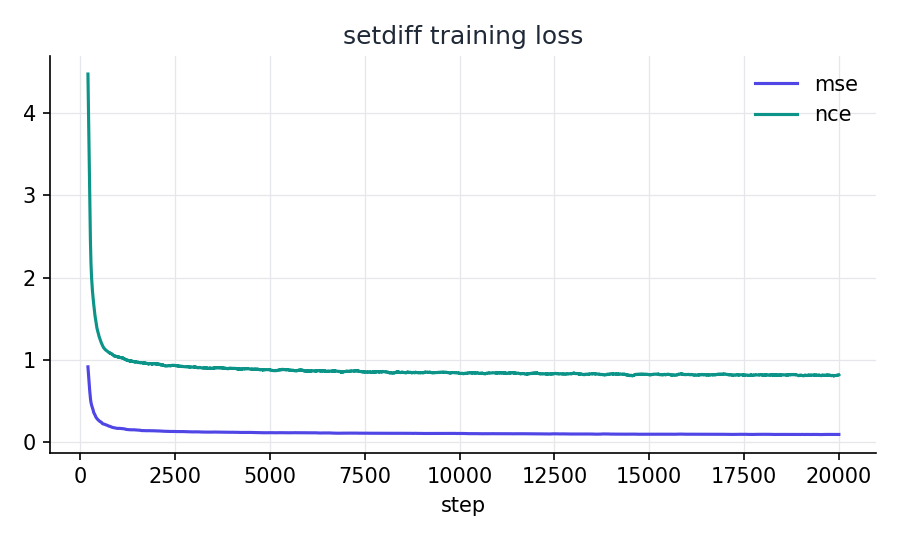

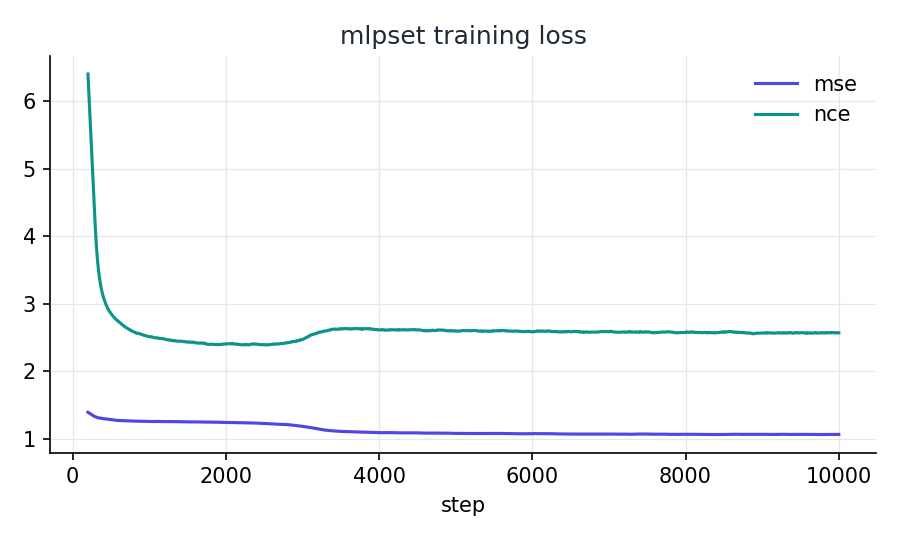

CPU times: user 1h 25min 44s, sys: 8.59 s, total: 1h 25min 52s
Wall time: 1h 26min 1s


In [24]:
%%time
P.stage_setdiff(); P.stage_mlpset()
persist()
for f in ["fig_loss_setdiff.png", "fig_loss_mlpset.png"]:
    display(Image(P.p(f)))

## 5. Doc channel, validation shortlists + rerankers, streaming test evaluation

In [29]:
import torch
from xmcdiff.xl import retrieval

def _init(self, E, device):
    self.device = device
    self.dt = torch.float16 if str(device).startswith("cuda") else torch.float32
    self.E = torch.as_tensor(E, device=device).to(self.dt)
    self.L, self.d = self.E.shape
    self.kind = "exact"

retrieval.GpuIndex.__init__ = _init

In [30]:
%%time
P.stage_docchannel(); P.stage_val(); P.stage_evaluate()
display(Markdown(open(P.p("results.md")).read()))
persist()

[docchannel] done in 343s
[val] a0: shortlists + rerankers in 12s
[val] mlpset: shortlists + rerankers in 140s
[val] setdiff: shortlists + rerankers in 606s
[evaluate] a0 done in 99s
[evaluate] mlpset done in 2696s
[evaluate] setdiff done in 12835s
## Test results (LF-AmazonTitles-1.3M)

| Method | P@1 | P@3 | P@5 | nDCG@5 | PSP@1 | PSP@3 | PSP@5 | PSnDCG@5 | coverage@5 | R@300 |
|---|---|---|---|---|---|---|---|---|---|---|
| A0 dual encoder (no diffusion) | 27.75 | 23.51 | 21.02 | 25.39 | 26.47 | 27.20 | 27.71 | 27.28 | 34.61 | 56.57 |
| A0 + reranker | 37.59 | 32.60 | 29.41 | 34.48 | 24.01 | 26.10 | 27.45 | 26.22 | 32.61 | 56.57 |
| MLP set prediction (deterministic) only + reranker | 37.66 | 31.70 | 27.83 | 32.94 | 20.78 | 23.08 | 24.43 | 22.99 | 29.38 | 27.98 |
| MLP set prediction (deterministic) only (vote) | 26.83 | 23.17 | 20.84 | 24.37 | 17.72 | 19.65 | 20.94 | 19.51 | 29.26 | 27.98 |
| MLP set prediction (deterministic) + doc channel + reranker | 37.47 | 32.31 | 29.12 | 34.1

## Test results (LF-AmazonTitles-1.3M)

| Method | P@1 | P@3 | P@5 | nDCG@5 | PSP@1 | PSP@3 | PSP@5 | PSnDCG@5 | coverage@5 | R@300 |
|---|---|---|---|---|---|---|---|---|---|---|
| A0 dual encoder (no diffusion) | 27.75 | 23.51 | 21.02 | 25.39 | 26.47 | 27.20 | 27.71 | 27.28 | 34.61 | 56.57 |
| A0 + reranker | 37.59 | 32.60 | 29.41 | 34.48 | 24.01 | 26.10 | 27.45 | 26.22 | 32.61 | 56.57 |
| MLP set prediction (deterministic) only + reranker | 37.66 | 31.70 | 27.83 | 32.94 | 20.78 | 23.08 | 24.43 | 22.99 | 29.38 | 27.98 |
| MLP set prediction (deterministic) only (vote) | 26.83 | 23.17 | 20.84 | 24.37 | 17.72 | 19.65 | 20.94 | 19.51 | 29.26 | 27.98 |
| MLP set prediction (deterministic) + doc channel + reranker | 37.47 | 32.31 | 29.12 | 34.12 | 22.85 | 24.96 | 26.39 | 25.17 | 30.06 | 56.72 |
| Set diffusion only + reranker | 31.34 | 25.94 | 22.57 | 26.63 | 16.54 | 18.08 | 18.95 | 17.60 | 24.20 | 23.31 |
| Set diffusion only (vote) | 11.50 | 10.44 | 9.68 | 10.78 | 6.02 | 7.46 | 8.47 | 7.19 | 12.90 | 23.31 |
| Set diffusion + doc channel + reranker (main) | 37.70 | 32.58 | 29.37 | 34.36 | 21.56 | 24.13 | 25.78 | 24.38 | 29.11 | 55.69 |
| Set diffusion + doc channel + reranker + tail boost (tau=0.1) | 36.89 | 31.88 | 28.76 | 33.79 | 23.47 | 25.65 | 27.07 | 25.90 | 31.32 | 55.69 |

## Recall@5 by label-frequency bucket

| Method | unseen (0) | 1-2 | 3-5 | 6-20 | >20 |
|---|---|---|---|---|---|
| A0 dual encoder (no diffusion) | 25.28 | 26.62 | 29.52 | 23.18 | 3.68 |
| A0 + reranker | 30.43 | 21.93 | 22.25 | 18.19 | 7.34 |
| MLP set prediction (deterministic) only + reranker | 16.04 | 16.57 | 17.49 | 14.41 | 7.39 |
| MLP set prediction (deterministic) only (vote) | 10.72 | 12.36 | 15.66 | 14.57 | 5.08 |
| MLP set prediction (deterministic) + doc channel + reranker | 24.09 | 22.17 | 21.85 | 16.29 | 7.44 |
| Set diffusion only + reranker | 8.60 | 9.33 | 11.25 | 10.67 | 6.23 |
| Set diffusion only (vote) | 1.49 | 1.98 | 3.57 | 5.01 | 2.69 |
| Set diffusion + doc channel + reranker (main) | 25.70 | 20.80 | 19.97 | 15.82 | 7.64 |
| Set diffusion + doc channel + reranker + tail boost (tau=0.1) | 28.98 | 23.80 | 22.88 | 17.57 | 7.13 |

## Predicted set size

| Model | slots used per doc (per sample) | true labels per doc |
|---|---|---|
| mlpset | 13.55 | 16.63 |
| setdiff | 21.68 | 16.63 |


persisted 31 items
CPU times: user 4h 36min 43s, sys: 5min 7s, total: 4h 41min 50s
Wall time: 4h 39min 8s


## 6. ANN (FAISS IVF) vs exact search, and efficiency

In [31]:
%%time
P.stage_ann(); P.stage_efficiency()
print(open(P.p("ann.json")).read()); print(open(P.p("efficiency.json")).read())
persist()

[ann] IVF built (lat 34s, full 93s)
[ann] {
 "n_docs": 5000,
 "nlist": 4096,
 "nprobe": 32,
 "metrics": {
  "exact": {
   "P@1": 26.260000228881836,
   "nDCG@1": 26.26,
   "PSP@1": 16.55889320373535,
   "PSnDCG@1": 16.558892881286816,
   "R@1": 3.926123373922547,
   "P@3": 23.093332290649414,
   "nDCG@3": 25.091588756322437,
   "PSP@3": 18.286788940429688,
   "PSnDCG@3": 17.82669980648294,
   "R@3": 8.060795503459453,
   "P@5": 20.808000564575195,
   "nDCG@5": 24.34960261579478,
   "PSP@5": 19.206541061401367,
   "PSnDCG@5": 18.53015881521719,
   "R@5": 10.802097519838561,
   "coverage@5": 7.876251061978076,
   "num_eval_docs": 5000,
   "R@300": 38.10087390174517
  },
  "ivf": {
   "P@1": 25.860000610351562,
   "nDCG@1": 25.86,
   "PSP@1": 16.17340660095215,
   "PSnDCG@1": 16.173409181330285,
   "R@1": 3.7277172755854493,
   "P@3": 22.746665954589844,
   "nDCG@3": 24.62892951986995,
   "PSP@3": 17.850770950317383,
   "PSnDCG@3": 17.337499364118372,
   "R@3": 7.7468061986124646,
   "P@5

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[efficiency] {
 "num_labels": 1305265,
 "n_docs": 2000,
 "batched_ms_per_doc": {
  "a0": {
   "queries_ms": 4.2319297790527344e-05,
   "retrieval_ms": 0.3864821195602417,
   "rerank_ms": 0.009152770042419434,
   "total_ms_incl_encoder": 0.7560665607452393
  },
  "mlpset": {
   "queries_ms": 0.0028231143951416016,
   "retrieval_ms": 3.313914656639099,
   "rerank_ms": 0.008983492851257324,
   "total_ms_incl_encoder": 3.6861106157302856
  },
  "setdiff": {
   "queries_ms": 4.897076725959778,
   "retrieval_ms": 9.964415669441223,
   "rerank_ms": 0.008912324905395508,
   "total_ms_incl_encoder": 15.230794072151184
  }
 },
 "encoder_ms_per_doc": 0.3603893518447876,
 "exhaustive_dot_all_labels_ms_per_doc": 0.2947772741317749,
 "params": {
  "encoder": 109482240,
  "setdiff": 21141249,
  "mlpset": 10266656,
  "reranker": 4865,
  "label_bank_floats": 1002443520,
  "latent_bank_floats": 334147840
 },
 "peak_gpu_mem_MB": 4420.759765625
}
{
  "n_docs": 5000,
  "nlist": 4096,
  "nprobe": 32,
  "met

## 8. Interface

In [40]:
LAUNCH_APP = True

In [41]:
if LAUNCH_APP:
    from xmcdiff.xl.app import XLPredictor, build_ui
    build_ui(XLPredictor(PERSIST)).launch(share=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://138d36d48b061921dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
